# QKD v2.1 — BB84 · SSP · E91 con stack crittografico post-quantum

**Autore:** Francesco Pisaturo — Università degli Studi di Salerno

Simulazione in NetSquid di tre protocolli QKD (BB84, SSP a sei stati, E91 entanglement-based) con l'intera
catena di post-processing: sifting, stima del QBER, riconciliazione Cascade, verifica della chiave,
Privacy Amplification Toeplitz, autenticazione post-quantum del canale classico (ML-DSA / SLH-DSA via liboqs),
chiave ibrida ML-KEM-768 + QKD via HKDF e cifratura AES-256-GCM.

### Estensioni rispetto alla versione 1.0
1. **Cascade completo** (Brassard & Salvail 1994): blocco adattivo $k_1=\lfloor 0.73/\mathrm{QBER}\rfloor$ (limitato per le chiavi corte), blocchi che raddoppiano a ogni passata, propagazione *cascade* completa tra le passate, 6 passate.
2. **Autenticazione post-quantum** del canale classico: ML-DSA-65 (FIPS 204) di default, SLH-DSA-SHAKE-128s (FIPS 205) selezionabile.
3. **Decoy states** (Hwang 2003, Lo-Ma-Chen 2005): sorgente laser attenuata poissoniana, lower bound LMC sul key rate, attacco PNS.
4. **Protocollo E91** (Ekert 1991): coppie $|\Phi^+\rangle$, test CHSH.
5. **KEM ibrido**: $K_{\text{finale}}=\mathrm{HKDF}(K_1\,\|\,K_2)$ con $K_1$ da ML-KEM-768 e $K_2$ dalla QKD.
6. **Jitter temporale dei rivelatori** come contributo al QBER.
7. **Attacco man-in-the-middle attivo** su canale quantistico e classico, con controllo negativo della firma.
8. **Key rate reale** con il costo in bit divulgati del Cascade completo.

### Struttura del notebook
| Sezione | Contenuto |
|---|---|
| 0 | Setup, dipendenze, costanti |
| Moduli 1–2 | Fisica del canale, protocolli BB84/SSP/E91 |
| Moduli 3–4 | Cascade, decoy states, firma PQ, KEM ibrido, Privacy Amplification |
| Modulo 2F | Attacco MITM attivo (usa la firma del Modulo 3C) |
| Moduli 5–7 | Runner unificato, AES-256-GCM, no-cloning e sicurezza E91 |
| Modulo 8 | Analisi (distanza, statistica, rumore, key rate, PA, modello fisico) |
| Moduli 9–10 | Dashboard e conclusioni |
| Fasi 0–9 | Esecuzione dell'esperimento, una cella per fase |

Le celle di definizione (moduli) non eseguono simulazioni: tutto il lavoro avviene nelle celle **Fase**, che
vanno eseguite in ordine. In fondo al notebook c'è il registro delle correzioni rispetto alla v2.0.

## 0 · Setup

**Dipendenze**
```
pip install --extra-index-url https://pypi.netsquid.org netsquid   # richiede l'account del forum NetSquid
pip install numpy scipy matplotlib cryptography
pip install liboqs-python    # firma e KEM post-quantum (compila liboqs al primo import: servono cmake e ninja)
pip install pyspx            # facoltativo: fallback SPHINCS+ se liboqs non è disponibile
```
Se liboqs non è attivo, la firma ricade su pyspx e il KEM su X25519: il notebook resta eseguibile, ma i risultati
**non** sono interamente post-quantum e il codice lo dichiara esplicitamente in output.

**Attenzione all'omonimia su PyPI:** `pip install oqs` installa *Open Quick Script*, un pacchetto che non c'entra
nulla con la crittografia e occupa lo stesso nome di modulo. Il rilevamento qui sotto verifica l'API, non solo l'import.

In [1]:
import os, math, hashlib, random, time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from numpy.lib.stride_tricks import sliding_window_view
from scipy.special import erfc

import netsquid as ns
import netsquid.qubits.qubitapi as qapi
from netsquid.nodes import Node
from netsquid.components import QuantumChannel
from netsquid.components.models import FibreDelayModel
from netsquid.components.models.qerrormodels import DepolarNoiseModel
from netsquid.protocols import NodeProtocol

from cryptography.hazmat.primitives.ciphers.aead import AESGCM
from cryptography.hazmat.primitives.kdf.hkdf import HKDF
from cryptography.hazmat.primitives import hashes as _hashes
from cryptography.hazmat.primitives import serialization as _serialization
from cryptography.hazmat.primitives.asymmetric.x25519 import X25519PrivateKey, X25519PublicKey

# ── liboqs (Open Quantum Safe) ────────────────────────────────────────
# liboqs-python, se la libreria C non è compilata e la compilazione fallisce,
# chiama sys.exit(): SystemExit eredita da BaseException, non da Exception,
# quindi va catturato BaseException per non interrompere il notebook.
_OQS_DIAGNOSTIC = None
try:
    import oqs as _oqs
    _missing = [a for a in ("get_enabled_sig_mechanisms", "get_enabled_kem_mechanisms",
                            "Signature", "KeyEncapsulation") if not hasattr(_oqs, a)]
    if _missing:
        raise ImportError("il modulo 'oqs' importato NON è liboqs-python (mancano: "
                          + ", ".join(_missing) + "): probabile conflitto con il "
                          "pacchetto PyPI omonimo 'oqs' (Open Quick Script).")
    _enabled_sigs = set(_oqs.get_enabled_sig_mechanisms())
    _enabled_kems = set(_oqs.get_enabled_kem_mechanisms())
except BaseException as _e:
    _oqs, _enabled_sigs, _enabled_kems = None, set(), set()
    _OQS_DIAGNOSTIC = f"{type(_e).__name__}: {_e}"

# ── pyspx (fallback SPHINCS+), importato solo se serve ───────────────
_sphincs = None
if _oqs is None:
    try:
        import pyspx.shake_128s as _sphincs
    except BaseException:
        _sphincs = None

# S† (Sdg) non è garantito come builtin in ogni versione di NetSquid
_SDG = getattr(ns, "Sdg", None) or ns.Operator("Sdg", np.array([[1, 0], [0, -1j]], dtype=complex))

# Cartella delle figure: relativa al notebook, funziona su Windows, macOS e Linux
OUTPUT_DIR = os.path.abspath("qkd_output")
os.makedirs(OUTPUT_DIR, exist_ok=True)

ns.sim_reset()
_oqs_label = (f"liboqs {_oqs.oqs_version()}" if _oqs is not None and hasattr(_oqs, "oqs_version")
              else ("liboqs" if _oqs is not None else
                    ("pyspx (fallback, liboqs assente)" if _sphincs else "nessuna libreria di firma PQ")))
print(f"NetSquid {ns.__version__} | {_oqs_label} | cryptography (HKDF, AES-GCM)")
print(f"Figure salvate in: {OUTPUT_DIR}")

liboqs-python faulthandler is disabled
NetSquid 1.1.8 | liboqs 0.16.0 | cryptography (HKDF, AES-GCM)
Figure salvate in: /home/franciscodev/progetto_bb84/qkd_output


### Costanti fisiche, di protocollo e utilità comuni

In [2]:
FIBRE_ATTENUATION_DB_PER_KM = 0.1419   # dB/km — fibra ULL (PSCF)
QBER_THRESHOLD_BB84 = 11.0             # %
QBER_THRESHOLD_SSP  = 12.6             # %
QBER_THRESHOLD_E91  = 11.0             # % (equivalente a BB84)
QBER_THRESHOLDS = {"BB84": QBER_THRESHOLD_BB84, "SSP": QBER_THRESHOLD_SSP, "E91": QBER_THRESHOLD_E91}

DARK_COUNT_RATE_HZ = 10.0     # Hz — SNSPD stato dell'arte
DETECTOR_GATE_NS   = 1.0      # ns — finestra del rivelatore
LIGHT_SPEED_FIBRE  = 2e8      # m/s
PMD_COEFFICIENT_PS = 0.06     # ps/√km — fibra PSCF ULL

JITTER_SNSPD_PS  = 50.0       # ps — SNSPD (10-100 ps tipico)
JITTER_INGAAS_PS = 400.0      # ps — InGaAs/InP commerciale
CLOCK_PERIOD_NS  = 1.0        # ns — sistema a 1 GHz

MU_SIGNAL, MU_DECOY1, MU_DECOY2 = 0.5, 0.1, 0.0   # intensità segnale / decoy / vuoto

# E91: Alice misura a 0°, 45°, 90°; Bob a 45°, 90°, 135° (angoli sul cerchio X-Z di Bloch).
# Coppie CHSH: (0°,45°), (0°,135°), (90°,45°), (90°,135°). Basi uguali (45°/90°) → chiave.
E91_ALICE_ANGLES = [0.0, 45.0, 90.0]
E91_BOB_ANGLES   = [45.0, 90.0, 135.0]

# Cascade: con chiavi di poche centinaia di bit e pochi errori, blocchi grandi quanto la chiave lasciano
# sfuggire coppie di errori. Limiti scelti con un test su 300 sessioni simulate per configurazione (Modulo 3).
CASCADE_PASSES = 6              # passate del Cascade completo
CASCADE_K1_MAX_FRACTION = 4     # blocco iniziale ≤ n/4
CASCADE_BLOCK_MAX_FRACTION = 2  # nessun blocco oltre n/2

SECURITY_PARAM   = 64   # bit sottratti dalla PA (≈ 2·log2(1/ε))
VERIFY_TAG_BITS  = 32   # bit del tag di verifica della chiave riconciliata (divulgati)
MIN_SIFTED_BITS  = 20   # sotto questa soglia la sessione non è eseguibile


def set_global_seed(seed=None):
    """Seed di numpy e random: rende riproducibili scelte di base, perdite e permutazioni."""
    if seed is None:
        seed = int(np.random.default_rng().integers(0, 2**31))
    np.random.seed(seed)
    random.seed(seed)
    return seed


def banner(title, width=70, char="═"):
    print("\n" + char * width + f"\n  {title}\n" + char * width)


def bits_to_bytes(bits):
    """Impacchetta una lista di bit (MSB first) in bytes; la lunghezza è implicita in len(bits)."""
    return np.packbits(np.asarray(bits, dtype=np.uint8)).tobytes()


set_global_seed(42)
print("Costanti e utilità caricate (seed iniziale 42).")

Costanti e utilità caricate (seed iniziale 42).


## Modulo 1 · Fisica del canale

Contributi al QBER, sommati e poi troncati al 50% (oltre, il canale non trasporta informazione):
- **ottico** (disallineamento, 0.5%) e **depolarizzazione** (`base_noise/2`);
- **PMD**: $\mathrm{DGD}=c_{\mathrm{PMD}}\sqrt{d}$, confrontato con il bit slot;
- **dark count**: $p_{\mathrm{dark}}/\bigl(2(p_{\mathrm{signal}}+p_{\mathrm{dark}})\bigr)$;
- **jitter** (modello gaussiano, Hadfield 2009): $\mathrm{QBER}_j=\tfrac12\,\mathrm{erfc}\!\bigl(T_{\mathrm{slot}}/(2\sqrt2\,\sigma_j)\bigr)$.

Valori del jitter con clock a 1 GHz: SNSPD 50 ps → ≈7.6·10⁻²² %, SNSPD 100 ps → ≈2.9·10⁻⁵ %,
InGaAs 400 ps → ≈10.6 % (con slot di 2 ns scende a ≈0.62 %). Con InGaAs a 1 GHz il jitter è il fattore dominante.

La perdita in fibra (Beer-Lambert) è campionata come binomiale, senza alcun minimo artificiale:
se non arriva nessun fotone, la sessione è dichiarata impossibile.

In [3]:
def photon_survival_probability(distance_km):
    return 10 ** (-FIBRE_ATTENUATION_DB_PER_KM * distance_km / 10)


def compute_pmd_qber(distance_km, pmd_coeff=PMD_COEFFICIENT_PS):
    dgd_ps = pmd_coeff * math.sqrt(distance_km)
    return min(0.5 * (dgd_ps / 1000.0) * 100, 50.0)       # bit slot = 1000 ps


def compute_dark_count_qber(distance_km, dark_rate_hz=DARK_COUNT_RATE_HZ, gate_ns=DETECTOR_GATE_NS):
    eta_detector = 0.9 if dark_rate_hz <= 100 else 0.20    # SNSPD vs InGaAs
    p_signal = photon_survival_probability(distance_km) * eta_detector
    p_dark = dark_rate_hz * gate_ns * 1e-9
    denom = 2.0 * (p_signal + p_dark)
    return min((p_dark / denom * 100) if denom > 1e-30 else 50.0, 50.0)


def compute_jitter_qber(jitter_ps=JITTER_SNSPD_PS, clock_period_ns=CLOCK_PERIOD_NS, detector_type="SNSPD"):
    """Frazione (in %) di click che il jitter sposta nel bin adiacente."""
    sigma = JITTER_INGAAS_PS if detector_type == "InGaAs" else jitter_ps
    if sigma <= 0:
        return 0.0
    x = clock_period_ns * 1000.0 / (2.0 * math.sqrt(2.0) * sigma)
    return min(erfc(x) / 2.0 * 100.0, 50.0)


def compute_total_physical_qber(distance_km, base_noise=0.0, pmd_coeff=PMD_COEFFICIENT_PS,
                                dark_rate_hz=DARK_COUNT_RATE_HZ, detector_type="SNSPD",
                                jitter_ps=JITTER_SNSPD_PS, clock_period_ns=CLOCK_PERIOD_NS):
    """QBER fisico totale (%). 'dominant' è il contributo più grande tra i cinque."""
    dr = 10000.0 if detector_type == "InGaAs" else dark_rate_hz
    jp = JITTER_INGAAS_PS if detector_type == "InGaAs" else jitter_ps
    parts = {
        "ottico": 0.5,
        "depol":  base_noise / 2 * 100,
        "pmd":    compute_pmd_qber(distance_km, pmd_coeff),
        "dark":   compute_dark_count_qber(distance_km, dark_rate_hz=dr),
        "jitter": compute_jitter_qber(jp, clock_period_ns, detector_type),
    }
    raw = sum(parts.values())
    return {
        "distance_km": distance_km, "detector": detector_type,
        "qber_optical": parts["ottico"], "qber_depol": parts["depol"], "qber_pmd": parts["pmd"],
        "qber_dark": parts["dark"], "qber_jitter": parts["jitter"],
        "qber_total": min(raw, 50.0),
        "qber_total_unclamped": raw,          # diagnostico: valore prima del clamp
        "qber_saturated": raw > 50.0,
        "dominant": max(parts, key=parts.get),
    }


def apply_photon_loss(num_bits, distance_km, min_photons=0):
    """Fotoni sopravvissuti alla tratta (binomiale). Ritorna (arrivati, p_sopravvivenza)."""
    p = photon_survival_probability(distance_km)
    return max(int(np.random.binomial(num_bits, p)), min_photons), p


def apply_detector_jitter(key_bob, detector="SNSPD"):
    """Inverte la frazione di bit di Bob attesa dal jitter del rivelatore. Ritorna il QBER da jitter (%)."""
    qber_j = compute_jitter_qber(detector_type=detector)
    n_flips = min(int(round(len(key_bob) * qber_j / 100.0)), len(key_bob))
    if n_flips > 0:
        for idx in np.random.choice(len(key_bob), size=n_flips, replace=False):
            key_bob[idx] = 1 - key_bob[idx]
    return qber_j

print("Modulo 1 (fisica del canale + jitter) caricato.")

Modulo 1 (fisica del canale + jitter) caricato.


## Modulo 2A-D · Protocolli NetSquid: BB84, SSP e Eve intercept-resend

Codifica comune: base 0 = Z (|0⟩,|1⟩), base 1 = X (|+⟩,|−⟩), base 2 = Y (|+i⟩,|−i⟩, solo SSP).
Misura nella base Y: S† seguito da H, poi misura in Z. Alice, Bob ed Eve condividono gli stessi
due helper di codifica e misura, così che BB84 e SSP differiscano solo per il numero di basi.

In [4]:
def encode_qubit(bit, basis):
    """Prepara un qubit con il bit nella base data (0=Z, 1=X, 2=Y)."""
    q, = qapi.create_qubits(1)
    if bit == 1:
        qapi.operate(q, ns.X)
    if basis >= 1:
        qapi.operate(q, ns.H)
    if basis == 2:
        qapi.operate(q, ns.S)
    return q


def measure_in_basis(qubit, basis):
    if basis == 2:
        qapi.operate(qubit, _SDG)
    if basis >= 1:
        qapi.operate(qubit, ns.H)
    res, _ = qapi.measure(qubit, ns.Z)
    return int(res)


class AlicePrepareProtocol(NodeProtocol):
    """Alice prepare-and-measure: invia un qubit per nanosecondo sulla porta cout_q."""
    def __init__(self, node, bits, bases):
        super().__init__(node)
        self.bits, self.bases = bits, bases

    def run(self):
        for bit, basis in zip(self.bits, self.bases):
            self.node.ports["cout_q"].tx_output(encode_qubit(bit, basis))
            yield self.await_timer(1)


class BobMeasureProtocol(NodeProtocol):
    """Bob prepare-and-measure: misura ogni qubit ricevuto nella base scelta."""
    def __init__(self, node, bases):
        super().__init__(node)
        self.bases = bases
        self.results = np.zeros(len(bases), dtype=int)

    def run(self):
        for i, basis in enumerate(self.bases):
            yield self.await_port_input(self.node.ports["cin_q"])
            qubit = self.node.ports["cin_q"].rx_input().items[0]
            self.results[i] = measure_in_basis(qubit, basis)


def _build_channel(name, distance, noise_rate):
    """Canale quantistico in fibra con depolarizzazione indipendente dal tempo (probabilità noise_rate)."""
    return QuantumChannel(name, length=distance, models={
        "delay_model": FibreDelayModel(),
        "quantum_noise_model": DepolarNoiseModel(depolar_rate=noise_rate, time_independent=True)})


def _empty_stats(protocol, distance_km, noise, eve_present, photons_sent, photons_arrived,
                 survival_prob, mode=None, threshold=None, abort_reason=None, **extra):
    """Statistiche di una sessione abortita prima del post-processing (stesse chiavi di una sessione completa)."""
    stats = {
        "protocol": protocol, "mode": mode or protocol, "distance_km": distance_km, "noise": noise,
        "eve_present": eve_present, "intercept_rate": 0.0,
        "photons_sent": photons_sent, "photons_arrived": photons_arrived, "survival_prob": survival_prob,
        "raw_len": 0, "sift_ratio": 0.0, "errors_raw": 0, "qber": 0.0, "qber_post_rec": 0.0,
        "qber_jitter": 0.0, "bits_disclosed": 0, "blocks_fixed": 0, "cascade_passes": 0,
        "cascade_overhead": 0, "key_verified": False,
        "threshold": threshold if threshold is not None else QBER_THRESHOLDS.get(protocol, QBER_THRESHOLD_BB84),
        "safe": False, "abort_reason": abort_reason,
        "decoy": None, "auth": None, "mlkem": None,
        "pa": None, "pa_output_bits": 0, "pa_available_bits": 0,
    }
    stats.update(extra)
    return stats


# I nomi della v2.0 restano disponibili: BB84 e SSP differiscono solo per le basi passate
AliceBB84Protocol = AliceSSPProtocol = AlicePrepareProtocol
BobBB84Protocol = BobSSPProtocol = BobMeasureProtocol


class EveInterceptResendProtocol(NodeProtocol):
    """Eve intercetta una frazione intercept_rate dei qubit, misura in una base casuale e ritrasmette."""
    def __init__(self, node, num_bits, num_bases=2, intercept_rate=1.0):
        super().__init__(node)
        self.num_bits = num_bits
        self.intercept_mask = np.random.random(num_bits) < intercept_rate
        self.eve_bases = np.random.randint(num_bases, size=num_bits)
        self.eve_results = np.zeros(num_bits, dtype=int)

    def run(self):
        for i in range(self.num_bits):
            yield self.await_port_input(self.node.ports["cin_q"])
            qubit = self.node.ports["cin_q"].rx_input().items[0]
            if self.intercept_mask[i]:
                b = self.eve_bases[i]
                self.eve_results[i] = measure_in_basis(qubit, b)
                qubit = encode_qubit(self.eve_results[i], b)
            self.node.ports["cout_q"].tx_output(qubit)
            yield self.await_timer(1)


def run_prepare_measure_session(num_bits, distance, noise_rate, protocol="BB84",
                                eve_present=False, intercept_rate=1.0):
    """
    Fase quantistica di BB84/SSP: perdita fotonica, trasmissione (con Eve opzionale a metà tratta),
    misure e sifting. Ritorna un dict con le chiavi siftate di Alice e Bob (None se non arriva nulla).
    """
    ns.sim_reset()
    num_bases = 3 if protocol == "SSP" else 2
    effective, p_survive = apply_photon_loss(num_bits, distance)
    out = {"effective": effective, "p_survive": p_survive, "key_alice": [], "key_bob": [],
           "alice_bases": None}
    if effective < 1:
        return out

    alice, bob = Node("Alice", port_names=["cout_q"]), Node("Bob", port_names=["cin_q"])
    a_bits = np.random.randint(2, size=effective)
    a_bases = np.random.randint(num_bases, size=effective)
    b_bases = np.random.randint(num_bases, size=effective)
    alice_p = AlicePrepareProtocol(alice, a_bits, a_bases)
    bob_p = BobMeasureProtocol(bob, b_bases)
    protocols = [alice_p, bob_p]

    if eve_present:                     # Eve a metà tratta: due canali da d/2, rumore diviso a metà
        eve = Node("Eve", port_names=["cin_q", "cout_q"])
        ch1 = _build_channel("AliceEve", distance / 2, noise_rate / 2)
        ch2 = _build_channel("EveBob", distance / 2, noise_rate / 2)
        alice.ports["cout_q"].connect(ch1.ports["send"]); ch1.ports["recv"].connect(eve.ports["cin_q"])
        eve.ports["cout_q"].connect(ch2.ports["send"]); ch2.ports["recv"].connect(bob.ports["cin_q"])
        protocols.append(EveInterceptResendProtocol(eve, effective, num_bases, intercept_rate))
    else:
        ch = _build_channel("AliceBob", distance, noise_rate)
        alice.ports["cout_q"].connect(ch.ports["send"]); ch.ports["recv"].connect(bob.ports["cin_q"])
    for p in protocols:
        p.start()
    ns.sim_run()

    same = a_bases == b_bases
    out.update(key_alice=[int(x) for x in a_bits[same]], key_bob=[int(x) for x in bob_p.results[same]],
               alice_bases=a_bases)
    return out

print("Modulo 2A-D (BB84 / SSP / Eve IR) caricato.")

Modulo 2A-D (BB84 / SSP / Eve IR) caricato.


## Modulo 2E · Protocollo E91 (Ekert 1991)

Una sorgente centrale prepara $|\Phi^+\rangle=(|00\rangle+|11\rangle)/\sqrt2$ e invia un qubit ad Alice e uno a Bob,
ciascuno su una tratta di lunghezza $d/2$. Per misurare lungo l'angolo di Bloch θ si applica $R_y(-\theta)$ e si misura
in Z; con $|\Phi^+\rangle$ la correlazione è $E(a,b)=\cos(a-b)$ e con gli angoli di Ekert $S=2\sqrt2$.

$$S=\bigl|E(0°,45°)-E(0°,135°)+E(90°,45°)+E(90°,135°)\bigr|,\qquad S\le 2 \text{ (classico)},\quad S=2\sqrt2 \text{ (QM)}$$

**Incertezza statistica.** Ogni correlazione è stimata solo sulle coppie con quella combinazione di angoli (1/9 del
totale). Con $N$ campioni $\sigma_E=\sqrt{(1-E^2)/N}$ e $\sigma_S=\sqrt{\sum\sigma_E^2}$: con ~800 coppie
$\sigma_S\approx0.2$, quindi una stima di $S$ oltre $2\sqrt2$ è una fluttuazione, non una violazione della meccanica
quantistica. S va sempre riportato come $S\pm\sigma_S$, insieme alla distanza dal limite classico in unità di σ.

**Perdita fotonica.** Le due tratte da $d/2$ danno $P(d/2)^2=P(d)$: in fibra la perdita è *identica* a BB84 sulla
stessa distanza. Lo svantaggio di E91 in questo modello è il sifting: le basi coincidono solo in 2 casi su 9 (≈22%,
contro ≈50% di BB84). Nei sistemi reali si aggiunge la richiesta di coincidenza tra due rivelatori ($\eta_{det}^2$).

Il rumore di canale è lo stesso di BB84 (depolarizzazione `noise_rate/2` per tratta); un eventuale rumore della
sorgente si imposta separatamente con `source_noise` (default 0).

In [5]:
_RY_OPERATOR_CACHE = {}

def _get_ry_operator(angle_deg):
    """Operatore R_y(θ) costruito come matrice (None per θ=0). Per misurare a θ si usa R_y(-θ)."""
    key = round(angle_deg % 360, 6)
    if key == 0.0:
        return None
    if key not in _RY_OPERATOR_CACHE:
        t = math.radians(angle_deg) / 2.0
        _RY_OPERATOR_CACHE[key] = ns.Operator(
            f"Ry_{key:.3f}", np.array([[math.cos(t), -math.sin(t)], [math.sin(t), math.cos(t)]], dtype=complex))
    return _RY_OPERATOR_CACHE[key]


class E91MeasureProtocol(NodeProtocol):
    """Parte di misura di E91: ogni qubit ricevuto è misurato lungo l'angolo scelto."""
    def __init__(self, node, angle_choices):
        super().__init__(node)
        self.angle_choices = angle_choices
        self.results = np.zeros(len(angle_choices), dtype=int)

    def run(self):
        for i, angle in enumerate(self.angle_choices):
            yield self.await_port_input(self.node.ports["cin_q"])
            qubit = self.node.ports["cin_q"].rx_input().items[0]
            op = _get_ry_operator(-angle)
            if op is not None:
                qapi.operate(qubit, op)
            self.results[i], _ = qapi.measure(qubit, ns.Z)


class AliceE91Protocol(E91MeasureProtocol):
    """Alice in E91 (angoli 0°, 45°, 90°)."""


class BobE91Protocol(E91MeasureProtocol):
    """Bob in E91 (angoli 45°, 90°, 135°)."""


class EntanglementSourceProtocol(NodeProtocol):
    """Sorgente di coppie |Φ+⟩. noise_rate = imperfezione della SORGENTE (Pauli casuale), distinta dal canale."""
    def __init__(self, node, n_pairs, noise_rate=0.0):
        super().__init__(node)
        self.n_pairs, self.noise_rate = n_pairs, noise_rate

    def run(self):
        for _ in range(self.n_pairs):
            q_a, q_b = qapi.create_qubits(2)
            qapi.operate(q_a, ns.H)
            qapi.operate([q_a, q_b], ns.CNOT)
            for q in (q_a, q_b):
                if self.noise_rate > 0 and np.random.random() < self.noise_rate:
                    qapi.operate(q, [ns.X, ns.Y, ns.Z][np.random.randint(3)])
            self.node.ports["cout_alice"].tx_output(q_a)
            self.node.ports["cout_bob"].tx_output(q_b)
            yield self.await_timer(1)


_CHSH_PAIRS = ((0, 45), (0, 135), (90, 45), (90, 135))


def _chsh_correlations(alice_results, bob_results, alice_angles, bob_angles):
    """Per ciascuna coppia CHSH: (E, N) = correlazione stimata e numero di campioni."""
    a = 1 - 2 * np.asarray(alice_results)          # 0 → +1, 1 → −1
    b = 1 - 2 * np.asarray(bob_results)
    aa, bb = np.asarray(alice_angles), np.asarray(bob_angles)
    out = []
    for ang_a, ang_b in _CHSH_PAIRS:
        m = (np.abs(aa - ang_a) < 1e-6) & (np.abs(bb - ang_b) < 1e-6)
        out.append((float(np.mean(a[m] * b[m])) if m.any() else 0.0, int(m.sum())))
    return out


def compute_chsh_parameter(alice_results, bob_results, alice_angles, bob_angles):
    """Ritorna (S, E(0,45), E(0,135), E(90,45), E(90,135))."""
    (e11, _), (e13, _), (e31, _), (e33, _) = _chsh_correlations(alice_results, bob_results,
                                                                 alice_angles, bob_angles)
    return abs(e11 - e13 + e31 + e33), e11, e13, e31, e33


def compute_chsh_uncertainty(alice_results, bob_results, alice_angles, bob_angles):
    """
    Deviazione standard di S. Ogni prodotto vale ±1, quindi Var = 1 − E² e σ_E = √((1 − E²)/N);
    i quattro termini sono indipendenti (coppie di angoli disgiunte): σ_S = √(Σ σ_E²).
    Con N ≈ 85 per termine σ_S ≈ 0.2: un valore stimato oltre 2√2 è una fluttuazione statistica.
    """
    terms = _chsh_correlations(alice_results, bob_results, alice_angles, bob_angles)
    if any(n == 0 for _, n in terms):
        return float("inf")
    return math.sqrt(sum((1 - e * e) / n for e, n in terms))


def run_e91_protocol(num_pairs=400, distance=30.0, noise_rate=0.02, verbose=True,
                     source_noise=0.0, jitter_detector="SNSPD"):
    """
    Fase quantistica di E91: distribuzione, misure, test CHSH, sifting, QBER.
    Ritorna (is_safe, key_alice | None, stats); stats["key_bob"] contiene la chiave di Bob.
    """
    ns.sim_reset()
    effective, p_survive = apply_photon_loss(num_pairs, distance)
    base = {"protocol": "E91", "mode": "E91", "distance_km": distance, "noise": noise_rate,
            "eve_present": False, "photons_sent": num_pairs, "photons_arrived": effective,
            "survival_prob": p_survive, "threshold": QBER_THRESHOLD_E91}
    if effective < 1:
        if verbose:
            print(f"\n[E91] {distance}km: nessuna coppia arrivata (p={p_survive:.2e}) — sessione impossibile")
        return False, None, _empty_stats(**base, abort_reason="fotoni")
    if verbose:
        print(f"\n[E91] {effective}/{num_pairs} coppie entangled | {distance}km | rumore {noise_rate*100:.1f}%")

    a_ang = np.random.choice(E91_ALICE_ANGLES, size=effective)
    b_ang = np.random.choice(E91_BOB_ANGLES, size=effective)

    source = Node("Source", port_names=["cout_alice", "cout_bob"])
    alice, bob = Node("Alice", port_names=["cin_q"]), Node("Bob", port_names=["cin_q"])
    for port, dest, name in (("cout_alice", alice, "Source→Alice"), ("cout_bob", bob, "Source→Bob")):
        ch = _build_channel(name, distance / 2, noise_rate / 2)
        source.ports[port].connect(ch.ports["send"])
        ch.ports["recv"].connect(dest.ports["cin_q"])
    src_p = EntanglementSourceProtocol(source, effective, source_noise)
    alice_p, bob_p = AliceE91Protocol(alice, a_ang), BobE91Protocol(bob, b_ang)
    src_p.start(); alice_p.start(); bob_p.start()
    ns.sim_run()

    S, e11, e13, e31, e33 = compute_chsh_parameter(alice_p.results, bob_p.results, a_ang, b_ang)
    S_sigma = compute_chsh_uncertainty(alice_p.results, bob_p.results, a_ang, b_ang)
    chsh_ok = S > 2.0
    chsh_signif = (S - 2.0) / S_sigma if S_sigma > 0 else 0.0     # distanza dal limite classico in σ

    same = np.abs(a_ang - b_ang) < 1e-6                 # basi condivise (45°,45°) e (90°,90°)
    key_alice = [int(x) for x in alice_p.results[same]]
    key_bob = [int(x) for x in bob_p.results[same]]
    raw_len = len(key_alice)
    if raw_len < MIN_SIFTED_BITS:
        if verbose:
            print("[E91] Troppo pochi bit di sifting")
        return False, None, _empty_stats(**base, S_chsh=S, S_sigma=S_sigma, chsh_ok=chsh_ok,
                                         abort_reason="sifting")

    qber_jitter = apply_detector_jitter(key_bob, jitter_detector)
    errors = sum(x != y for x, y in zip(key_alice, key_bob))
    qber = errors / raw_len * 100
    is_safe = chsh_ok and qber <= QBER_THRESHOLD_E91

    if verbose:
        over = " — oltre 2√2 per fluttuazione statistica" if S > 2 * math.sqrt(2) else ""
        print(f"[E91] CHSH S = {S:.3f} ± {S_sigma:.3f} ({'✓ > 2' if chsh_ok else '✗ ≤ 2'}, "
              f"{chsh_signif:.1f}σ dal limite classico{over})")
        print(f"[E91] Sifting: {raw_len} bit | QBER: {qber:.2f}%")
        print(f"[E91] E(0°,45°)={e11:.3f}  E(0°,135°)={e13:.3f}  E(90°,45°)={e31:.3f}  E(90°,135°)={e33:.3f}")
        print(f"[E91] {'✓ test CHSH e QBER superati' if is_safe else '✗ NON SICURO'}")

    stats = dict(base, raw_len=raw_len, sift_ratio=raw_len / effective, errors_raw=errors, qber=qber,
                 qber_jitter=qber_jitter, S_chsh=S, S_sigma=S_sigma, chsh_signif=chsh_signif, chsh_ok=chsh_ok,
                 E_a1b1=e11, E_a1b3=e13, E_a3b1=e31, E_a3b3=e33, safe=is_safe,
                 abort_reason=None if is_safe else ("CHSH" if not chsh_ok else "QBER"),
                 key_bob=key_bob if is_safe else None,
                 sift_message=np.concatenate([a_ang, b_ang]).astype(np.uint8).tobytes())
    return is_safe, key_alice if is_safe else None, stats

print("Modulo 2E (E91 + CHSH) caricato.")

Modulo 2E (E91 + CHSH) caricato.


## Modulo 3 · Riconciliazione: Cascade completo (Brassard & Salvail 1994)

Per ogni passata $j$: blocchi di dimensione $k_j=2^j k_1$ con $k_1=\lfloor 0.73/\mathrm{QBER}\rfloor$ su una
permutazione casuale della chiave; Alice annuncia la parità di ogni blocco (1 bit divulgato). Un blocco con parità
discordante viene corretto per bisezione (1 bit divulgato per livello). **Effetto cascade:** il bit corretto
appartiene a un blocco in ciascuna delle altre passate; quei blocchi, di cui Bob conosce già la parità di Alice,
diventano dispari e vengono corretti a loro volta, fino a esaurimento. Le parità già annunciate non vengono
ridivulgate. Ogni bit annunciato è registrato in `parity_log`, che il Modulo 3C firma.

**Chiavi corte.** La regola $k_1=0.73/\mathrm{QBER}$ è pensata per chiavi lunghe. Con poche centinaia di bit e
QBER basso il blocco iniziale diventa grande quanto la chiave, e una coppia di errori nello stesso blocco può
sfuggire a tutte le passate. Per questo il blocco iniziale è limitato a $n/4$, nessun blocco supera $n/2$ e le
passate sono 6. Test su 300 sessioni simulate per configurazione (percentuale di sessioni con errori residui):

| n, QBER | 4 passate, senza limiti | limiti, 4 passate | **limiti, 6 passate** (scelta) |
|---|---|---|---|
| 190 bit, 1.6% | 13.3% | 4.3% | **1.3%** |
| 370 bit, 0.5% | 8.3% | 1.3% | **0.3%** |
| 370 bit, 2.0% | 10.7% | 5.0% | **1.3%** |
| 730 bit, 0.5% | 14.0% | 5.0% | **0.7%** |
| 730 bit, 1.0% | 9.0% | 7.3% | **2.0%** |

Il costo è di circa 8-10 bit divulgati in più per sessione. Le sessioni residue sono intercettate dal tag di verifica.

`information_reconciliation()` conserva il Cascade semplificato della v1.0 (blocco fisso, 2 passate indipendenti,
senza propagazione) come baseline: con un numero pari di errori nello stesso blocco la parità concorda e
l'errore passa inosservato.

Riferimento: G. Brassard, L. Salvail, *Secret-key reconciliation by public discussion*,
EUROCRYPT '93, LNCS 765, pp. 410–423 (1994).

In [6]:
def cascade_reconciliation_full(key_alice, key_bob, qber_estimate=0.05, n_passes=CASCADE_PASSES):
    """Cascade completo. Ritorna (chiave_alice, chiave_bob_corretta, stats)."""
    n = min(len(key_alice), len(key_bob))
    ka = np.array(key_alice[:n], dtype=np.uint8)
    kb = np.array(key_bob[:n], dtype=np.uint8)
    errors_before = int(np.sum(ka != kb))
    k1 = max(1, int(0.73 / max(qber_estimate, 0.001)))
    k1 = min(k1, max(1, n // CASCADE_K1_MAX_FRACTION))        # chiavi corte: almeno 4 blocchi nella passata 1
    k_max = max(1, n // CASCADE_BLOCK_MAX_FRACTION)           # e nessun blocco più grande di metà chiave

    perms, inv_perms, sizes = [], [], []
    alice_par = []                 # alice_par[p][block] = parità annunciata da Alice
    parity_log = []
    disclosed = fixed = 0

    def par(arr, p, lo, hi):
        return int(arr[perms[p][lo:hi]].sum()) & 1      # int() prima di &: compatibile con NumPy 1.x e 2.x

    def announce(p, lo, hi):
        nonlocal disclosed
        v = par(ka, p, lo, hi)
        parity_log.append(v)
        disclosed += 1
        return v

    def bisect_and_fix(p, lo, hi):
        """Blocco [lo,hi) della passata p con parità dispari: trova e corregge un errore."""
        nonlocal fixed
        while hi - lo > 1:
            mid = (lo + hi) // 2
            if announce(p, lo, mid) != par(kb, p, lo, mid):
                hi = mid
            else:
                lo = mid
        idx = int(perms[p][lo])
        kb[idx] ^= 1
        fixed += 1
        return idx

    for j in range(n_passes):
        k = min(k1 * 2 ** j, k_max)
        perm = list(range(n)); random.shuffle(perm)
        perm = np.array(perm, dtype=np.int64)
        inv = np.empty(n, dtype=np.int64); inv[perm] = np.arange(n)
        perms.append(perm); inv_perms.append(inv); sizes.append(k)
        alice_par.append([announce(j, lo, min(lo + k, n)) for lo in range(0, n, k)])

        # Blocchi dispari da correggere: (passata, indice blocco). Si parte dai più piccoli.
        pending = [(j, b) for b, v in enumerate(alice_par[j])
                   if v != par(kb, j, b * k, min(b * k + k, n))]
        while pending:
            pending.sort(key=lambda t: sizes[t[0]])
            p, b = pending.pop(0)
            lo, hi = b * sizes[p], min(b * sizes[p] + sizes[p], n)
            if alice_par[p][b] == par(kb, p, lo, hi):
                continue                        # già sistemato da un'altra correzione
            idx = bisect_and_fix(p, lo, hi)
            for q in range(j + 1):              # effetto cascade sulle passate già eseguite
                bq = int(inv_perms[q][idx]) // sizes[q]
                lo_q, hi_q = bq * sizes[q], min(bq * sizes[q] + sizes[q], n)
                if alice_par[q][bq] != par(kb, q, lo_q, hi_q) and (q, bq) not in pending:
                    pending.append((q, bq))

    errors_after = int(np.sum(ka != kb))
    simple_est = int(n / k1 + n / (2 * k1) + fixed * math.log2(max(k1, 2)))   # stima 2 passate senza cascade
    stats = {
        "errors_before": errors_before, "errors_after": errors_after, "blocks_fixed": fixed,
        "bits_disclosed": disclosed, "n_passes": n_passes, "k1_blocksize": k1,
        "cascade_overhead": max(disclosed - simple_est, 0), "simple_disclosed": simple_est,
        "correction_rate": (errors_before - errors_after) / max(errors_before, 1),
        "parity_log": parity_log,
    }
    return ka.tolist(), kb.tolist(), stats


def information_reconciliation(key_alice, key_bob, block_size=8):
    """Cascade SEMPLIFICATO v1.0 (baseline): blocco fisso, 2 passate indipendenti, nessuna propagazione."""
    n = min(len(key_alice), len(key_bob))
    ka = list(key_alice[:n]); kb = list(key_bob[:n])
    errors_before = sum(a != b for a, b in zip(ka, kb))
    parity_log, fixed = [], 0

    def run_pass(order):
        nonlocal fixed
        for start in range(0, n, block_size):
            idx = order[start:start + block_size]
            pa = sum(ka[i] for i in idx) % 2
            parity_log.append(pa)
            if pa == sum(kb[i] for i in idx) % 2:
                continue
            lo, hi = 0, len(idx)
            while hi - lo > 1:
                mid = (lo + hi) // 2
                pa_half = sum(ka[i] for i in idx[lo:mid]) % 2
                parity_log.append(pa_half)
                if pa_half != sum(kb[i] for i in idx[lo:mid]) % 2:
                    hi = mid
                else:
                    lo = mid
            kb[idx[lo]] = 1 - kb[idx[lo]]
            fixed += 1

    run_pass(list(range(n)))                 # passata 1: blocchi lineari
    perm = list(range(n)); random.shuffle(perm)
    run_pass(perm)                           # passata 2: permutazione casuale indipendente

    stats = {"errors_before": errors_before, "errors_after": sum(a != b for a, b in zip(ka, kb)),
             "blocks_fixed": fixed, "bits_disclosed": len(parity_log), "n_passes": 2,
             "k1_blocksize": block_size, "cascade_overhead": 0, "parity_log": parity_log}
    return ka, kb, stats

print("Modulo 3 (Cascade completo + baseline semplificata v1.0) caricato.")

Modulo 3 (Cascade completo + baseline semplificata v1.0) caricato.


## Modulo 3B · Decoy states (Hwang 2003, Lo-Ma-Chen 2005)

Con un laser attenuato il numero di fotoni per impulso è poissoniano: con $\mu=0.5$ circa il 9% degli impulsi ha
$n\ge2$ fotoni ed è vulnerabile al *Photon-Number-Splitting* (Eve trattiene un fotone e lo misura dopo il sifting).
Alternando intensità segnale e decoy, Alice stima i parametri del singolo fotone e ottiene il lower bound

$$R \ge Q_1\,[1-H(e_1)] - Q_\mu\, f\, H(E_\mu),\qquad f=1.16$$

Stima a due intensità più vuoto (Ma, Qi, Zhao, Lo, *PRA* 72, 012326, 2005, eq. 34 e 37):

$$Y_1^L=\frac{\mu}{\mu\nu-\nu^2}\Bigl[Q_\nu e^{\nu}-Q_\mu e^{\mu}\frac{\nu^2}{\mu^2}-\frac{\mu^2-\nu^2}{\mu^2}Y_0\Bigr],\quad
Q_1^L=\mu e^{-\mu}Y_1^L,\quad e_1^U=\frac{E_\nu Q_\nu e^{\nu}-e_0Y_0}{Y_1^L\,\nu}$$

Nel modello di canale senza Eve il bound restituisce il 97-99% del vero $Y_1=\eta+Y_0-\eta Y_0$ su 10-200 km.
`R_ideal` è un'approssimazione di riferimento, $Q_\mu(1-2H(E_\mu))$, senza correzione per i multi-fotone.

In [7]:
def _h2(x):
    """Entropia binaria di Shannon."""
    x = max(1e-10, min(x, 1 - 1e-10))
    return -x * math.log2(x) - (1 - x) * math.log2(1 - x)


def poisson_photon_distribution(mu, max_n=20):
    return np.array([math.exp(-mu) * mu ** n / math.factorial(n) for n in range(max_n + 1)])


def decoy_state_gain_qber(mu, distance_km, noise_rate=0.04, eta_bob=0.9,
                          dark_rate=DARK_COUNT_RATE_HZ, gate_ns=DETECTOR_GATE_NS):
    """Gain Q_μ e QBER E_μ attesi per un impulso di intensità μ."""
    eta_total = photon_survival_probability(distance_km) * eta_bob
    Y0 = dark_rate * gate_ns * 1e-9
    Q_mu = 1 - math.exp(-eta_total * mu) + Y0
    e_opt = noise_rate / 2 + 0.005
    E_mu = min((Y0 / 2 + e_opt * (1 - math.exp(-eta_total * mu))) / max(Q_mu, 1e-10), 0.5)
    p1 = mu * math.exp(-mu)
    return {"mu": mu, "Q_mu": Q_mu, "E_mu": E_mu, "p1_mu": p1,
            "p_multi_mu": 1 - math.exp(-mu) - p1, "eta_total": eta_total}


def estimate_single_photon_params(mu_s, mu_d1, mu_d2, Qs, Qd1, Qd2, Es, Ed1, e0=0.5):
    """Ritorna (Q1_lower, e1_upper, Y1_lower) — Ma et al. 2005, eq. 34 e 37."""
    Y0 = max(Qd2, 1e-10)
    denom = mu_s * mu_d1 - mu_d1 ** 2
    if abs(denom) < 1e-12:
        Y1 = 0.0
    else:
        bracket = (Qd1 * math.exp(mu_d1) - Qs * math.exp(mu_s) * mu_d1 ** 2 / mu_s ** 2
                   - (mu_s ** 2 - mu_d1 ** 2) / mu_s ** 2 * Y0)
        Y1 = max(mu_s / denom * bracket, 0.0)
    Q1 = mu_s * math.exp(-mu_s) * Y1
    if Y1 < 1e-12 or mu_d1 < 1e-12:
        e1 = 0.5
    else:
        e1 = min(max((Ed1 * Qd1 * math.exp(mu_d1) - e0 * Y0) / (Y1 * mu_d1), 0.0), 0.5)
    return Q1, e1, Y1


def compute_lmc_key_rate(mu_s=MU_SIGNAL, mu_d1=MU_DECOY1, mu_d2=MU_DECOY2,
                         distance_km=30.0, noise_rate=0.04, f_reconciliation=1.16):
    s, d1, d2 = (decoy_state_gain_qber(m, distance_km, noise_rate) for m in (mu_s, mu_d1, mu_d2))
    Q1, e1, _ = estimate_single_photon_params(mu_s, mu_d1, mu_d2, s["Q_mu"], d1["Q_mu"], d2["Q_mu"],
                                              s["E_mu"], d1["E_mu"])
    R_lower = max(0.0, Q1 * (1 - _h2(e1)) - s["Q_mu"] * f_reconciliation * _h2(s["E_mu"]))
    R_ideal = max(0.0, s["Q_mu"] * (1 - 2 * _h2(s["E_mu"])))
    return {"distance_km": distance_km, "mu_signal": mu_s, "Q_signal": s["Q_mu"], "E_signal": s["E_mu"],
            "Q_decoy1": d1["Q_mu"], "Q1_lower": Q1, "e1_upper": e1,
            "R_lmc_lower": R_lower, "R_ideal": R_ideal,
            "ratio_decoy_ideal": R_lower / max(R_ideal, 1e-10),
            "pns_vulnerable": s["p_multi_mu"], "p_multiphoton": s["p_multi_mu"]}


def run_decoy_analysis(distances=None, mu_s=MU_SIGNAL, mu_d1=MU_DECOY1, noise_rate=0.04, verbose=True):
    distances = distances or [10, 20, 30, 50, 75, 100, 150, 200]
    if verbose:
        banner(f"DECOY STATES — key rate LMC vs sorgente ideale (mu_s={mu_s}, mu_d={mu_d1})", 78)
        print(f"  {'Dist':>6} | {'Q_s':>8} | {'E_s%':>6} | {'Q1':>9} | {'e1%':>6} | "
              f"{'R_LMC':>9} | {'R_ideal':>9} | {'R_LMC/R_id':>10}")
        print("  " + "─" * 78)
    results = []
    for d in distances:
        r = compute_lmc_key_rate(mu_s=mu_s, mu_d1=mu_d1, distance_km=d, noise_rate=noise_rate)
        results.append(r)
        if verbose:
            print(f"  {d:>5}km | {r['Q_signal']:>8.5f} | {r['E_signal']*100:>5.2f}% | {r['Q1_lower']:>9.6f} | "
                  f"{r['e1_upper']*100:>5.2f}% | {r['R_lmc_lower']:>9.6f} | {r['R_ideal']:>9.6f} | "
                  f"{r['ratio_decoy_ideal']:>10.2f}")
    if verbose:
        print(f"\n  mu={mu_s}: P(n≥2) = {results[0]['p_multiphoton']*100:.1f}% degli impulsi vulnerabili al PNS")
        print("  I decoy permettono di stimare Q1 ed e1 → lower bound sicuro sul key rate.")
    return results

print("Modulo 3B (decoy states) caricato.")

Modulo 3B (decoy states) caricato.


## Modulo 3C · Autenticazione post-quantum del canale classico

| Schema | Famiglia | pk | firma | Sicurezza |
|---|---|---|---|---|
| **ML-DSA-65** (FIPS 204, ex Dilithium) — *default* | reticoli (Module-LWE/SIS) | 1952 B | 3309 B | NIST livello 3 |
| SLH-DSA-SHAKE-128s (FIPS 205, ex SPHINCS+) | solo hash (SHAKE-256) | 32 B | 7856 B | NIST livello 1 |

**Perché ML-DSA di default.** Ogni messaggio classico (basi, parità, seme della PA, conferma) porta una firma, e una
sessione a 25-30 km produce poche centinaia di bit di chiave: con SLH-DSA la firma pesa più del doppio in banda ed è
ordini di grandezza più lenta (il benchmark della Fase 0 lo misura sulla macchina in uso).

**Prezzo dichiarato.** Con ML-DSA-65 e ML-KEM-768 (Modulo 3D) firma e KEM poggiano sulla stessa famiglia di problemi
(reticoli): le loro sicurezze non sono indipendenti. Resta indipendente $K_2$, la chiave QKD, information-theoretic:
se i reticoli cadessero cadrebbero $K_1$ e la firma (il MITM tornerebbe possibile per le sessioni future), non le
chiavi già stabilite. Chi preferisce la diversificazione delle assunzioni imposta `SIG_ALG_PRIMARY = SIG_ALG_ALT`.

**Nomi degli algoritmi.** liboqs ha cambiato più volte i nomi (SPHINCS+ → SLH-DSA → `SLH_DSA_PURE_SHAKE_128S` da
liboqs 0.14): la tabella di alias li prova tutti. Se liboqs manca si usa pyspx (SPHINCS+-SHAKE-128s) con la stessa API.

Il test di correttezza controlla **entrambe** le direzioni: firma valida accettata, messaggio manomesso e chiave
pubblica errata rifiutati. Una verifica che accetta tutto renderebbe vuota ogni conclusione sul MITM.

In [8]:
SIG_ALG_PRIMARY = "ML-DSA-65"            # lattice-based, FIPS 204 (default)
SIG_ALG_ALT     = "SLH-DSA-SHAKE-128s"   # hash-based, FIPS 205 (alternativa)

_SIG_ALG_ALIASES = {
    "ML-DSA-65": ["ML-DSA-65", "Dilithium3"],
    "SLH-DSA-SHAKE-128s": ["SLH_DSA_PURE_SHAKE_128S", "SLH-DSA-SHAKE-128s",
                           "SPHINCS+-SHAKE-128s-simple", "SPHINCS+-SHAKE-128s"],
}
_SPHINCS_SEED_LEN = 48


def _resolve_sig_alg(alg_name):
    """Nome FIPS → nome abilitato nella build di liboqs installata (None se assente)."""
    return next((c for c in _SIG_ALG_ALIASES.get(alg_name, [alg_name]) if c in _enabled_sigs), None)


# Backend effettivo: liboqs con l'algoritmo primario, poi l'alternativo, poi pyspx
SIG_ALG_ACTIVE = None
if _oqs is not None:
    SIG_ALG_ACTIVE = _resolve_sig_alg(SIG_ALG_PRIMARY) or _resolve_sig_alg(SIG_ALG_ALT)
if SIG_ALG_ACTIVE is not None:
    SIGNATURE_BACKEND = "liboqs"
else:
    if _sphincs is None:
        try:
            import pyspx.shake_128s as _sphincs
        except BaseException:
            _sphincs = None
    SIGNATURE_BACKEND = "pyspx-fallback" if _sphincs is not None else "nessuno"
    SIG_ALG_ACTIVE = "SPHINCS+-SHAKE-128s (pyspx)" if _sphincs is not None else "nessuna firma disponibile"
PQ_SIGNATURE_AVAILABLE = SIGNATURE_BACKEND != "nessuno"


def print_oqs_diagnostic():
    """Stampa perché liboqs non è attivo (altrimenti il fallback sarebbe silenzioso)."""
    if _oqs is not None:
        print(f"[liboqs] attivo — {len(_enabled_sigs)} schemi di firma, {len(_enabled_kems)} KEM abilitati")
        return True
    print(f"[liboqs] NON attivo — firma: {SIGNATURE_BACKEND}, KEM: X25519")
    print(f"[liboqs] causa: {_OQS_DIAGNOSTIC}")
    diag = str(_OQS_DIAGNOSTIC)
    if "Open Quick Script" in diag:
        print("  Soluzione: pip uninstall -y oqs && pip install --force-reinstall liboqs-python")
    elif "shared librar" in diag or "SystemExit" in diag:
        print("  Soluzione: pip install cmake ninja, poi riavviare il kernel (liboqs si compila al primo import)")
    return False


def _require_signature():
    if not PQ_SIGNATURE_AVAILABLE:
        raise RuntimeError("Nessuna libreria di firma post-quantum: installare liboqs-python (o pyspx).")


def pq_generate_keypair(alg=None, seed=None):
    """
    Coppia di chiavi per la firma. Con liboqs la chiave privata resta dentro l'oggetto Signature,
    che viene restituito come 'secret key' opaca. Il seed vale solo per il fallback pyspx.
    """
    _require_signature()
    if SIGNATURE_BACKEND == "liboqs":
        signer = _oqs.Signature(_resolve_sig_alg(alg) if alg else SIG_ALG_ACTIVE)
        return signer.generate_keypair(), signer
    if seed is None:
        seed = os.urandom(_SPHINCS_SEED_LEN)
    elif len(seed) != _SPHINCS_SEED_LEN:
        seed = hashlib.shake_128(seed).digest(_SPHINCS_SEED_LEN)
    return _sphincs.generate_keypair(seed)


def pq_sign_message(message: bytes, sk) -> bytes:
    _require_signature()
    return sk.sign(message) if SIGNATURE_BACKEND == "liboqs" else _sphincs.sign(message, sk)


def pq_verify_message(message: bytes, signature: bytes, pk: bytes, alg=None) -> bool:
    """False (mai eccezioni) su firma non valida, messaggio manomesso o chiave errata."""
    try:
        if SIGNATURE_BACKEND == "liboqs":
            with _oqs.Signature(_resolve_sig_alg(alg) if alg else SIG_ALG_ACTIVE) as verifier:
                return bool(verifier.verify(message, signature, pk))
        return bool(_sphincs.verify(message, signature, pk))
    except Exception:
        return False


# Alias della v1.0 (quando la firma era SPHINCS+): puntano allo schema attivo, qualunque esso sia
sphincs_generate_keypair = pq_generate_keypair
sphincs_sign_message = pq_sign_message
sphincs_verify_message = pq_verify_message


def verify_signature_soundness(verbose=True):
    """Firma valida accettata; messaggio manomesso e chiave pubblica altrui rifiutati."""
    msg = b"BB84 sifting: basi di Alice, sessione 0x2A"
    pk, sk = pq_generate_keypair()
    sig = pq_sign_message(msg, sk)
    ok_genuine = pq_verify_message(msg, sig, pk)
    ok_tampered = pq_verify_message(msg + b"!", sig, pk)
    ok_wrong_key = pq_verify_message(msg, sig, pq_generate_keypair()[0])
    sound = ok_genuine and not ok_tampered and not ok_wrong_key
    if verbose:
        print(f"\n[FIRMA PQ] Test di correttezza ({SIG_ALG_ACTIVE}):")
        print(f"  Messaggio autentico:      {'✓ accettato' if ok_genuine else '✗ RIFIUTATO'}")
        print(f"  Messaggio manomesso:      {'✓ rifiutato' if not ok_tampered else '✗ ACCETTATO'}")
        print(f"  Chiave pubblica errata:   {'✓ rifiutato' if not ok_wrong_key else '✗ ACCETTATO'}")
        print(f"  Esito:                    {'✓ firma sana' if sound else '✗ FIRMA NON SANA'}")
    return {"genuine_ok": ok_genuine, "tampered_rejected": not ok_tampered,
            "wrong_key_rejected": not ok_wrong_key, "sound": sound}


def benchmark_signature_schemes(n_trials=3, msg_size=1024, verbose=True):
    """Tempi di keygen/sign/verify e dimensioni per ML-DSA-65 e SLH-DSA-SHAKE-128s (richiede liboqs)."""
    if SIGNATURE_BACKEND != "liboqs":
        if verbose:
            print("\n[BENCHMARK] Richiede liboqs — confronto ML-DSA/SLH-DSA saltato.")
        return None
    msg, rows = os.urandom(msg_size), []
    for label in (SIG_ALG_PRIMARY, SIG_ALG_ALT):
        name = _resolve_sig_alg(label)
        if name is None:
            if verbose:
                print(f"[BENCHMARK] {label} non abilitato in questa build di liboqs — saltato.")
            continue
        t = {"keygen": 0.0, "sign": 0.0, "verify": 0.0}
        for _ in range(n_trials):
            t0 = time.perf_counter(); signer = _oqs.Signature(name); pk = signer.generate_keypair()
            t1 = time.perf_counter(); sig = signer.sign(msg)
            t2 = time.perf_counter()
            with _oqs.Signature(name) as ver:
                ver.verify(msg, sig, pk)
            t3 = time.perf_counter()
            t["keygen"] += t1 - t0; t["sign"] += t2 - t1; t["verify"] += t3 - t2
        rows.append({"algorithm": label, "liboqs_name": name, "pk_bytes": len(pk), "sig_bytes": len(sig),
                     **{f"{k}_ms": v / n_trials * 1000 for k, v in t.items()},
                     "family": "hash-based" if "SLH" in label else "lattice-based"})
    if verbose and rows:
        banner("BENCHMARK FIRME POST-QUANTUM (liboqs) — costo dell'autenticazione", 78)
        print(f"  {'Algoritmo':<20} {'Famiglia':<14} {'pk':>7} {'firma':>8} {'keygen':>10} {'sign':>10} {'verify':>10}")
        print("  " + "─" * 76)
        for r in rows:
            print(f"  {r['algorithm']:<20} {r['family']:<14} {r['pk_bytes']:>6}B {r['sig_bytes']:>7}B "
                  f"{r['keygen_ms']:>8.2f}ms {r['sign_ms']:>8.2f}ms {r['verify_ms']:>8.2f}ms")
        fam = {r["family"]: r for r in rows}
        if len(fam) == 2:
            h, l = fam["hash-based"], fam["lattice-based"]
            print(f"\n  Hash-based / lattice-based: {h['sig_bytes']/l['sig_bytes']:.2f}× in banda, "
                  f"{h['sign_ms']/max(l['sign_ms'], 1e-9):.0f}× in tempo di firma")
        print(f"  Schema in uso nel progetto: {SIG_ALG_ACTIVE}")
    return rows


def authenticated_classical_exchange(alice_bases, alice_parity_bits, alice_sk, alice_pk,
                                     pa_seed=None, confirm_tag=None, verbose=True):
    """
    Firma e verifica TUTTI i messaggi classici della sessione: basi (sifting), parità del Cascade,
    seme della Privacy Amplification e tag di conferma della chiave. Include un controllo negativo:
    le basi manomesse con la firma originale devono essere rifiutate.
    """
    bases_msg = (bytes(alice_bases) if isinstance(alice_bases, (bytes, bytearray))
                 else np.asarray(alice_bases, dtype=np.uint8).tobytes())
    messages = {"basi": bases_msg, "parità Cascade": bits_to_bytes(alice_parity_bits or [])}
    if pa_seed is not None:
        messages["seme PA"] = pa_seed
    if confirm_tag is not None:
        messages["conferma chiave"] = confirm_tag

    signed = {}
    for name, m in messages.items():
        s = pq_sign_message(m, alice_sk)
        signed[name] = (s, pq_verify_message(m, s, alice_pk))
    tampered = bytearray(bases_msg)
    if tampered:
        tampered[0] ^= 0x01                                   # Eve altera una sola base
    forgery_rejected = not pq_verify_message(bytes(tampered), signed["basi"][0], alice_pk)
    overhead = sum(len(s) for s, _ in signed.values())
    all_valid = all(ok for _, ok in signed.values()) and forgery_rejected

    if verbose:
        print(f"\n[FIRMA PQ] Autenticazione canale classico [{SIG_ALG_ACTIVE} via {SIGNATURE_BACKEND}]:")
        print(f"  Chiave pubblica:  {len(alice_pk)}B → {alice_pk.hex()[:24]}...")
        for name, (s, ok) in signed.items():
            print(f"  Firma {name:<16} {len(s)}B → {'✓ valida' if ok else '✗ INVALIDA'}")
        print(f"  Basi manomesse:        → {'✓ rifiutate' if forgery_rejected else '✗ ACCETTATE (firma non sana!)'}")
        print(f"  Overhead totale:  {overhead/1024:.1f} KB per sessione ({len(signed)} messaggi firmati)")

    return {"ok_bases": signed["basi"][1], "ok_parity": signed["parità Cascade"][1],
            "messages_signed": list(signed), "forgery_rejected": forgery_rejected,
            "all_valid": all_valid, "sig_bases": signed["basi"][0], "overhead_bytes": overhead,
            "algorithm": SIG_ALG_ACTIVE, "backend": SIGNATURE_BACKEND}

print(f"Modulo 3C (firma PQ via {SIGNATURE_BACKEND} — {SIG_ALG_ACTIVE}) caricato.")

Modulo 3C (firma PQ via liboqs — ML-DSA-65) caricato.


## Modulo 3D · KEM ibrido: ML-KEM-768 + QKD via HKDF

La chiave di sessione deriva da due segreti indipendenti, così da sopravvivere alla rottura di uno dei due:

$$K_{\text{finale}} = \mathrm{HKDF\text{-}SHA256}\bigl(K_1\,\|\,K_2,\ \text{salt}=\text{session\_id}\bigr)$$

- $K_1$ = **ML-KEM-768** (FIPS 203, ex Kyber): pk 1184 B, sk 2400 B, ciphertext 1088 B, segreto 32 B. Sicurezza
  computazionale post-quantum (MLWE): una congettura, non un teorema.
- $K_2$ = **chiave QKD dopo la Privacy Amplification**: sicurezza information-theoretic, esposta però agli attacchi
  ai dispositivi reali (es. detector blinding). Usare la chiave *prima* della PA sarebbe un errore: contiene bit
  che Eve conosce dalle parità divulgate.

I due lati falliscono per cause scorrelate. **Fallback:** senza liboqs, $K_1$ viene da un DHKEM su X25519, sicuro
solo classicamente (cade con Shor) e dichiarato tale in `quantum_safe_k1=False`.
Le chiavi crittografiche non accettano seed: la riproducibilità del progetto è limitata alla parte fisica/QKD.

In [9]:
KEM_ALG_PRIMARY = "ML-KEM-768"
_KEM_ALG_ALIASES = {"ML-KEM-768": ["ML-KEM-768", "Kyber768"]}


def _resolve_kem_alg(alg_name):
    return next((c for c in _KEM_ALG_ALIASES.get(alg_name, [alg_name]) if c in _enabled_kems), None)


KEM_ALG_ACTIVE = _resolve_kem_alg(KEM_ALG_PRIMARY)
KEM_BACKEND = "liboqs" if KEM_ALG_ACTIVE else "x25519-fallback"


class HybridKEM:
    """KEM per K1: ML-KEM-768 reale con liboqs, DHKEM-X25519 (solo classico) altrimenti. Stessa API."""
    _HKDF_INFO = b"DHKEM-X25519-v1_ML-KEM-768-fallback"

    def __init__(self, alg=None):
        self.backend = KEM_BACKEND
        self.alg_name = alg or KEM_ALG_ACTIVE
        self.quantum_safe = self.backend == "liboqs"
        self.label = self.alg_name if self.quantum_safe else "X25519-DHKEM (fallback, NON quantum-safe)"

    def generate_keypair(self):
        if self.quantum_safe:
            kem = _oqs.KeyEncapsulation(self.alg_name)
            return kem.generate_keypair(), kem            # sk opaca: resta dentro l'oggetto
        sk = X25519PrivateKey.generate()
        pk = sk.public_key().public_bytes(_serialization.Encoding.Raw, _serialization.PublicFormat.Raw)
        return pk, sk.private_bytes(_serialization.Encoding.Raw, _serialization.PrivateFormat.Raw,
                                    _serialization.NoEncryption())

    def _derive_secret(self, dh_output):
        return HKDF(algorithm=_hashes.SHA256(), length=32, salt=None, info=self._HKDF_INFO).derive(dh_output)

    def encapsulate(self, pk):
        """Lato Bob: (ciphertext, shared_secret) dalla sola chiave pubblica."""
        if self.quantum_safe:
            with _oqs.KeyEncapsulation(self.alg_name) as kem:
                return kem.encap_secret(pk)
        eph = X25519PrivateKey.generate()
        ct = eph.public_key().public_bytes(_serialization.Encoding.Raw, _serialization.PublicFormat.Raw)
        return ct, self._derive_secret(eph.exchange(X25519PublicKey.from_public_bytes(pk)))

    def decapsulate(self, sk, ct):
        """Lato Alice: ricostruisce lo stesso segreto dal ciphertext."""
        if self.quantum_safe:
            return sk.decap_secret(ct)
        sk_obj = X25519PrivateKey.from_private_bytes(sk)
        return self._derive_secret(sk_obj.exchange(X25519PublicKey.from_public_bytes(ct)))


HybridKEM_X25519Placeholder = HybridKEM          # alias della v1.0


def mlkem_hkdf_hybrid_key(k1_kem: bytes, k2_qkd, session_id: bytes = None, output_len: int = 32) -> bytes:
    """HKDF(K1 ‖ K2). k2_qkd: bytes della chiave QKD dopo la PA (o lista di bit). Mai vuota."""
    k2 = bytes(k2_qkd) if isinstance(k2_qkd, (bytes, bytearray)) else bits_to_bytes(k2_qkd)
    if not k2:
        raise ValueError("K2 (chiave QKD) vuota: la chiave ibrida non può essere derivata.")
    return HKDF(algorithm=_hashes.SHA256(), length=output_len,
                salt=session_id if session_id is not None else os.urandom(32),
                info=b"QKD_HYBRIDKEM_HKDF_v2").derive(k1_kem + k2)


def run_hybrid_key_exchange(qkd_key, session_id=None, verbose=True, qkd_key_bob=None, protocol="QKD"):
    """
    Scambio ibrido KEM + QKD. qkd_key = K2 di Alice (bytes dopo la PA); qkd_key_bob = K2 di Bob
    (default uguale ad Alice). Ritorna (chiave_finale_alice, stats); stats["final_key_bob"] = chiave di Bob.
    """
    kem = HybridKEM()
    pk, sk = kem.generate_keypair()          # Alice
    ct, k1_bob = kem.encapsulate(pk)         # Bob
    k1_alice = kem.decapsulate(sk, ct)       # Alice
    sid = session_id or os.urandom(32)       # pubblico, inviato in chiaro con il ciphertext
    final_a = mlkem_hkdf_hybrid_key(k1_alice, qkd_key, sid)
    final_b = mlkem_hkdf_hybrid_key(k1_bob, qkd_key if qkd_key_bob is None else qkd_key_bob, sid)
    k2_bits = len(qkd_key) * 8 if isinstance(qkd_key, (bytes, bytearray)) else len(qkd_key)

    if verbose:
        print(f"\n[KEM ibrido + HKDF]  backend: {KEM_BACKEND} — {kem.label}")
        print(f"  pk: {len(pk)}B  ct: {len(ct)}B  K1: {k1_alice.hex()[:16]}... ({len(k1_alice)}B)  "
              f"K1 Alice=Bob: {'✓' if k1_alice == k1_bob else '✗'}")
        print(f"  K2 ({protocol}, dopo la PA): {k2_bits} bit")
        print(f"  K = HKDF(K1 ‖ K2, sid): {final_a.hex()[:32]}... ({len(final_a)*8} bit)  "
              f"Alice=Bob: {'✓' if final_a == final_b else '✗'}")
        print("  " + ("Entrambe le componenti sono post-quantum: K1 computazionale (MLWE), K2 information-theoretic"
                      if kem.quantum_safe else
                      "K1 solo classico (X25519): la resistenza quantistica è garantita SOLO da K2"))

    return final_a, {"pk_len": len(pk), "ct_len": len(ct), "k1_len": len(k1_alice),
                     "keys_match": k1_alice == k1_bob, "final_keys_match": final_a == final_b,
                     "qkd_bits": k2_bits, "final_key_bits": len(final_a) * 8,
                     "algorithm": f"{kem.label} + {protocol} + HKDF-SHA256", "backend": KEM_BACKEND,
                     "quantum_safe_k1": kem.quantum_safe, "final_key_bob": final_b}

print(f"Modulo 3D (KEM ibrido via {KEM_BACKEND} + HKDF) caricato.")

Modulo 3D (KEM ibrido via liboqs + HKDF) caricato.


## Modulo 4 · Privacy Amplification (Toeplitz) con tetto del Leftover Hash Lemma

$$\ell_{\text{out}} \le n_{\text{raw}} - \text{bit divulgati} - \text{parametro di sicurezza}$$

Emettere più bit di così non è prudenza discutibile: la chiave conterrebbe bit noti a Eve. Se $\ell_{\text{out}}\le 0$
(o $<128$ con `strict=True`) la sessione è **rifiutata**. La matrice di Toeplitz $T_{ij}=r_{i-j+n-1}$ è generata da un
**seme casuale nuovo a ogni sessione**, annunciato (e firmato) sul canale classico: la garanzia del Leftover Hash
Lemma richiede che la funzione di hash sia scelta a caso, non fissata in anticipo. Se servono 32 byte per AES-256
e i bit estratti sono meno di 256, l'espansione avviene via HKDF ed è dichiarata: HKDF non crea entropia.

In [10]:
def toeplitz_hash(bits, output_len, seed=None) -> bytes:
    """Hash di Toeplitz (famiglia 2-universale) di 'bits' su output_len bit, con matrice dal seme dato."""
    n = len(bits)
    if not 0 < output_len <= n:
        raise ValueError(f"output_len={output_len} non valido per n={n}: la PA deve comprimere.")
    seed_int = int.from_bytes(seed, "big") if isinstance(seed, (bytes, bytearray)) else seed
    r = np.random.default_rng(seed_int).integers(0, 2, size=n + output_len - 1, dtype=np.uint8)
    T = sliding_window_view(r, n)[:, ::-1]            # T[i, j] = r[i - j + n - 1]
    out = (T.astype(np.int64) @ np.asarray(bits, dtype=np.int64)) & 1
    return np.packbits(out.astype(np.uint8)).tobytes()


def secure_pa_output_length(n_raw, bits_disclosed, security_param=SECURITY_PARAM):
    return max(n_raw - bits_disclosed - security_param, 0)


def apply_privacy_amplification(raw_bits, bits_disclosed, security_param=SECURITY_PARAM,
                                max_output_bits=256, strict=True, seed=None):
    """Ritorna (key_bytes | None, stats). stats["seed"] è il seme pubblico della matrice di Toeplitz."""
    n = len(raw_bits)
    available = secure_pa_output_length(n, bits_disclosed, security_param)
    output_len = min(max_output_bits, available)
    seed = seed if seed is not None else np.random.bytes(16)
    stats = {"n_raw": n, "bits_disclosed": bits_disclosed, "security_param": security_param,
             "available_bits": available, "output_bits": output_len, "key_bits": output_len,
             "efficiency": output_len / n if n else 0.0, "aes256_capable": output_len >= 256,
             "rejected": False, "reason": None, "seed": seed}
    if output_len <= 0:
        reason = f"entropia residua nulla: {n} raw − {bits_disclosed} divulgati − {security_param} sicurezza ≤ 0"
    elif strict and output_len < 128:
        reason = f"solo {output_len} bit estraibili (< 128 minimi): sessione da scartare"
    else:
        return toeplitz_hash(raw_bits, output_len, seed), stats
    stats.update(rejected=True, reason=reason, output_bits=0, key_bits=0, aes256_capable=False)
    return None, stats


def expand_key_for_aes(key_bytes, stats):
    """32 byte per AES-256: diretti se ≥256 bit, altrimenti espansi via HKDF (entropia invariata, dichiarata)."""
    if len(key_bytes) >= 32:
        return key_bytes[:32]
    stats["expanded_to_aes256"] = True
    stats["effective_entropy_bits"] = stats["output_bits"]
    return HKDF(algorithm=_hashes.SHA256(), length=32, salt=None,
                info=b"QKD_PA_expand_to_AES256").derive(key_bytes)


def pa_key_for_aes(raw_bits, bits_disclosed, security_param=SECURITY_PARAM, strict=True, seed=None):
    """PA + adattamento a 32 byte. Ritorna (aes_key | None, stats)."""
    key, stats = apply_privacy_amplification(raw_bits, bits_disclosed, security_param, strict=strict, seed=seed)
    return (None, stats) if key is None else (expand_key_for_aes(key, stats), stats)

print("Modulo 4 (Privacy Amplification Toeplitz) caricato.")

Modulo 4 (Privacy Amplification Toeplitz) caricato.


## Modulo 2F · Attacco man-in-the-middle attivo

Eve controlla **entrambi** i canali. Sul quantistico fa intercept-resend; sul classico sostituisce l'annuncio delle
basi di Alice con le proprie. Bob "sifta" con le basi di Eve e stima il QBER contro i valori annunciati da Eve:
vede solo il rumore della tratta Eve→Bob, quindi l'attacco resta sotto soglia e invisibile, mentre Eve conosce
l'intera chiave di Bob. (Simmetricamente Eve chiude una seconda sessione con Alice.)

Con la firma post-quantum (Modulo 3C) il blocco è verificato con un **controllo negativo**: devono essere rifiutate
sia (a) le basi di Eve con la firma di Alice riusata, sia (b) le basi di Eve firmate con una chiave di Eve, mentre il
messaggio autentico di Alice deve essere accettato. La sola validità della firma legittima non dimostrerebbe nulla.

In [11]:
class EveMITMAttack:
    """Eve full-control. La fase quantistica è simulata in forma chiusa (senza NetSquid) per velocità."""

    def __init__(self, alice_bits, alice_bases, num_bases=2):
        self.alice_bits = np.asarray(alice_bits)
        self.alice_bases = np.asarray(alice_bases)
        n = len(alice_bits)
        self.eve_bases = np.random.randint(num_bases, size=n)
        same = self.eve_bases == self.alice_bases           # base giusta: bit di Alice, altrimenti casuale
        self.eve_results = np.where(same, self.alice_bits, np.random.randint(2, size=n))

    def mitm_sifting_no_auth(self, bob_bases, channel_noise=0.0):
        """
        Bob riceve i qubit preparati da Eve e le basi forgiate da Eve. Ritorna
        (chiave_bob, chiave_eve, QBER apparente %, bit compromessi).
        """
        bob_bases = np.asarray(bob_bases)
        flips = np.random.random(len(bob_bases)) < channel_noise / 2      # depolarizzazione Eve→Bob
        bob_results = np.where(bob_bases == self.eve_bases, self.eve_results ^ flips,
                               np.random.randint(2, size=len(bob_bases)))
        keep = bob_bases == self.eve_bases                                 # sifting con le basi di Eve
        key_bob, key_eve = bob_results[keep].tolist(), self.eve_results[keep].tolist()
        qber = float(np.mean(bob_results[keep] != self.eve_results[keep]) * 100) if keep.any() else 0.0
        return key_bob, key_eve, qber, len(key_eve)

    def mitm_sifting_with_pq_signature(self, bob_bases, alice_pk, alice_sk):
        alice_msg = self.alice_bases.astype(np.uint8).tobytes()
        eve_msg = self.eve_bases.astype(np.uint8).tobytes()
        sig = pq_sign_message(alice_msg, alice_sk)
        genuine_accepted = pq_verify_message(alice_msg, sig, alice_pk)
        replay_rejected = not pq_verify_message(eve_msg, sig, alice_pk)           # (a)
        _, eve_sk = pq_generate_keypair()
        forge_rejected = not pq_verify_message(eve_msg, pq_sign_message(eve_msg, eve_sk), alice_pk)  # (b)
        return {"mitm_blocked": genuine_accepted and replay_rejected and forge_rejected,
                "genuine_accepted": genuine_accepted, "replay_rejected": replay_rejected,
                "forge_rejected": forge_rejected, "msg": alice_msg, "sig": sig, "pk": alice_pk}

    def mitm_sifting_with_sphincs(self, bob_bases, alice_sphincs_pk, alice_sphincs_sk):
        """Alias v1.0: usa lo schema di firma attivo (non necessariamente SPHINCS+)."""
        r = self.mitm_sifting_with_pq_signature(bob_bases, alice_sphincs_pk, alice_sphincs_sk)
        return r["mitm_blocked"], r["msg"], r["sig"]


def simulate_mitm_comparison(num_bits=300, distance=30.0, noise_rate=0.04, verbose=True):
    if verbose:
        banner(f"ATTACCO MITM ATTIVO — confronto senza/con {SIG_ALG_ACTIVE}")
    effective, _ = apply_photon_loss(num_bits, distance)
    if effective < MIN_SIFTED_BITS:
        if verbose:
            print(f"  Troppo pochi fotoni a {distance}km — confronto non eseguibile.")
        return None
    alice_bits, alice_bases, bob_bases = (np.random.randint(2, size=effective) for _ in range(3))
    eve = EveMITMAttack(alice_bits, alice_bases, num_bases=2)
    key_bob, key_eve, qber_app, n_comp = eve.mitm_sifting_no_auth(bob_bases, channel_noise=noise_rate / 2)
    n_sift_legit = int(np.sum(alice_bases == bob_bases))
    threshold = QBER_THRESHOLD_BB84

    if verbose:
        print("\n  SCENARIO 1: senza autenticazione del canale classico")
        print(f"  Bit siftati attesi senza Eve: {n_sift_legit}")
        print(f"  Bit di Bob compromessi (MITM): {n_comp}")
        print(f"  QBER apparente: {qber_app:.2f}% (solo rumore Eve→Bob, soglia {threshold}%) "
              f"{'← EVE INVISIBILE' if qber_app <= threshold else ''}")
        n_diff = sum(a != b for a, b in zip(key_bob, key_eve))
        print(f"  Chiave Bob vs chiave Eve: {n_diff} bit diversi su {n_comp} (solo rumore, che Eve corregge "
              f"con la riconciliazione come farebbe Alice)")

    result = {"scenario_no_auth": {"bits_compromised": n_comp, "qber_apparent": qber_app,
                                   "mitm_success": qber_app <= threshold, "bits_sifted_legit": n_sift_legit}}
    if not PQ_SIGNATURE_AVAILABLE:
        if verbose:
            print("\n  SCENARIO 2 saltato: nessuna libreria di firma post-quantum disponibile.")
        return result

    pk, sk = pq_generate_keypair()
    r = eve.mitm_sifting_with_pq_signature(bob_bases, pk, sk)
    if verbose:
        print(f"\n  SCENARIO 2: con autenticazione {SIG_ALG_ACTIVE} ({SIGNATURE_BACKEND})")
        print(f"  Chiave pubblica Alice: {pk.hex()[:16]}... ({len(pk)}B) | firma: {len(r['sig'])}B")
        print(f"  Messaggio autentico di Alice accettato:  {'✓' if r['genuine_accepted'] else '✗'}")
        print(f"  Firma di Alice riusata su basi di Eve:   {'✓ rifiutata' if r['replay_rejected'] else '✗ ACCETTATA'}")
        print(f"  Basi di Eve firmate da Eve stessa:       {'✓ rifiutate' if r['forge_rejected'] else '✗ ACCETTATE'}")
        print(f"  MITM bloccato: {'✓ SÌ' if r['mitm_blocked'] else '✗ NO'}")
    result["scenario_with_auth"] = {k: r[k] for k in ("mitm_blocked", "genuine_accepted",
                                                       "replay_rejected", "forge_rejected")}
    result["scenario_with_auth"].update(sig_len=len(r["sig"]), pk_len=len(pk),
                                        algorithm=SIG_ALG_ACTIVE, backend=SIGNATURE_BACKEND)
    return result

print("Modulo 2F (MITM attivo) caricato.")

Modulo 2F (MITM attivo) caricato.


## Modulo 5 · Runner unificato BB84 / SSP / E91

Flusso di una sessione:
1. perdita fotonica (+ analisi decoy se richiesta, solo BB84/SSP);
2. fase quantistica con Eve opzionale (BB84/SSP) o distribuzione entangled + CHSH (E91);
3. sifting e jitter dei rivelatori → QBER;
4. riconciliazione (Cascade completo o semplificato);
5. **verifica della chiave**: Alice e Bob confrontano un tag hash a 32 bit (divulgati) — se differisce, la sessione
   è abortita, perché Alice e Bob avrebbero chiavi diverse;
6. Privacy Amplification con seme casuale → $K_2$;
7. [opzionale] firma post-quantum di tutti i messaggi classici;
8. [opzionale] chiave ibrida $\mathrm{HKDF}(K_1\|K_2)$;
9. decisione: QBER sotto soglia, CHSH (E91), verifica, PA e firme tutte superate.

Ritorna `(is_safe, chiave_finale_alice | None, stats)`; `stats["abort_reason"]` dice **perché** una sessione
non è sicura (`fotoni`, `sifting`, `QBER`, `CHSH`, `verifica`, `PA`, `firma`).

In [12]:
def _postprocess_key(key_alice, key_bob, qber_pct, sift_message, protocol, *, use_full_cascade=True,
                     cascade_passes=CASCADE_PASSES, use_pq_auth=False, use_mlkem_hybrid=False, pa_strict=False,
                     verbose=True):
    """Passi 4-8 comuni a tutti i protocolli. Ritorna (chiave_alice, chiave_bob, dict di statistiche)."""
    if use_full_cascade:
        ka, kb, rec = cascade_reconciliation_full(key_alice, key_bob, max(qber_pct / 100, 0.001), cascade_passes)
    else:
        ka, kb, rec = information_reconciliation(key_alice, key_bob)
    n = len(ka)

    # Verifica: tag SHA-256 troncato. I suoi bit si sommano a quelli divulgati.
    tag_a = hashlib.sha256(bits_to_bytes(ka)).digest()[:VERIFY_TAG_BITS // 8]
    tag_b = hashlib.sha256(bits_to_bytes(kb)).digest()[:VERIFY_TAG_BITS // 8]
    verified = tag_a == tag_b
    disclosed = rec["bits_disclosed"] + VERIFY_TAG_BITS

    key_a, pa_stats = apply_privacy_amplification(ka, disclosed, SECURITY_PARAM, strict=pa_strict)
    key_b = toeplitz_hash(kb, pa_stats["output_bits"], pa_stats["seed"]) if key_a is not None else None

    out = {"rec": rec, "qber_post_rec": rec["errors_after"] / n * 100 if n else 0.0,
           "key_verified": verified, "bits_disclosed": disclosed, "pa": pa_stats, "auth": None, "mlkem": None}
    if verbose:
        mode = f"Cascade completo, {rec['n_passes']} passate" if use_full_cascade else "Cascade semplificato"
        print(f"[REC] {mode}: {rec['bits_disclosed']} parità + {VERIFY_TAG_BITS} tag = {disclosed} bit divulgati | "
              f"errori {rec['errors_before']} → {rec['errors_after']} | "
              f"verifica {'✓ chiavi identiche' if verified else '✗ chiavi DIVERSE'}")
        if key_a is None:
            print(f"[PA]  ✗ rifiutata — {pa_stats['reason']}")
        else:
            print(f"[PA]  {n} raw − {disclosed} div. − {SECURITY_PARAM} sic. = {pa_stats['available_bits']} "
                  f"estraibili → {pa_stats['output_bits']} bit emessi"
                  + ("" if pa_stats["aes256_capable"] else " (< 256: espansi via HKDF per AES, entropia invariata)"))

    if use_pq_auth:
        if PQ_SIGNATURE_AVAILABLE:
            pk, sk = pq_generate_keypair()
            out["auth"] = authenticated_classical_exchange(sift_message, rec["parity_log"], sk, pk,
                                                           pa_seed=pa_stats["seed"], confirm_tag=tag_a,
                                                           verbose=verbose)
        else:                                   # richiesta ma impossibile: la sessione non è autenticata
            out["auth"] = {"all_valid": False, "backend": SIGNATURE_BACKEND, "algorithm": SIG_ALG_ACTIVE}
            if verbose:
                print("[FIRMA PQ] nessuna libreria di firma: autenticazione NON eseguita → sessione non sicura")

    final_a = final_b = None
    if key_a is not None and verified:
        final_a, final_b = expand_key_for_aes(key_a, pa_stats), expand_key_for_aes(key_b, dict(pa_stats))
        if use_mlkem_hybrid:
            final_a, out["mlkem"] = run_hybrid_key_exchange(key_a, verbose=verbose, qkd_key_bob=key_b,
                                                            protocol=protocol)
            final_b = out["mlkem"].pop("final_key_bob")
    return final_a, final_b, out


def run_qkd_protocol(num_bits=300, distance=30.0, noise_rate=0.04, eve_present=False, protocol="BB84",
                     verbose=True, intercept_rate=1.0, use_full_cascade=True, cascade_passes=CASCADE_PASSES,
                     use_pq_auth=False, use_decoy_states=False, use_mlkem_hybrid=False,
                     jitter_detector="SNSPD", pa_strict=False, use_sphincs_auth=None):
    """Sessione QKD completa. use_sphincs_auth è il nome v2.0 di use_pq_auth (mantenuto per compatibilità)."""
    if use_sphincs_auth is not None:
        use_pq_auth = use_sphincs_auth
    threshold = QBER_THRESHOLDS[protocol]

    # ── Fase quantistica ─────────────────────────────────────
    if protocol == "E91":
        if eve_present and verbose:
            print("[E91] Eve intercept-resend non è modellata per E91: sessione eseguita senza Eve.")
        is_ok, key_alice, e91 = run_e91_protocol(num_bits, distance, noise_rate, verbose=verbose,
                                                 jitter_detector=jitter_detector)
        key_bob, sift_message = e91.pop("key_bob", None), e91.pop("sift_message", None)
        stats = _empty_stats("E91", distance, noise_rate, False, num_bits, e91.get("photons_arrived", 0),
                             e91.get("survival_prob", 0.0))
        stats.update(e91)                       # stesse chiavi di BB84/SSP, più quelle specifiche di E91
        if not is_ok:
            return False, None, stats
        decoy_info = None
    else:
        q = run_prepare_measure_session(num_bits, distance, noise_rate, protocol, eve_present, intercept_rate)
        effective, p_survive = q["effective"], q["p_survive"]
        base = dict(protocol=protocol, distance_km=distance, noise=noise_rate, eve_present=eve_present,
                    photons_sent=num_bits, photons_arrived=effective, survival_prob=p_survive,
                    mode=f"{protocol}+Eve({intercept_rate*100:.0f}%)" if eve_present else protocol)
        if effective < 1:
            if verbose:
                print(f"\n[QKD] {protocol} | {distance}km: nessun fotone arrivato (p={p_survive:.2e})")
            return False, None, _empty_stats(**base, abort_reason="fotoni")
        decoy_info = (compute_lmc_key_rate(MU_SIGNAL, MU_DECOY1, distance_km=distance, noise_rate=noise_rate)
                      if use_decoy_states else None)
        if verbose:
            print(f"\n[QKD] {protocol} | {'⚠ EVE' if eve_present else '✓ no Eve'} | {effective}/{num_bits} fotoni "
                  f"({p_survive*100:.1f}%) | {distance}km | rumore {noise_rate*100:.1f}%")
            if decoy_info:
                print(f"[DECOY] mu_s={MU_SIGNAL} | Q1={decoy_info['Q1_lower']:.6f} | "
                      f"PNS-vulnerabili: {decoy_info['pns_vulnerable']*100:.1f}%")
        key_alice, key_bob = q["key_alice"], q["key_bob"]
        raw_len = len(key_alice)
        if raw_len < MIN_SIFTED_BITS:
            return False, None, _empty_stats(**base, raw_len=raw_len, abort_reason="sifting")
        qber_jitter = apply_detector_jitter(key_bob, jitter_detector)
        errors = sum(a != b for a, b in zip(key_alice, key_bob))
        stats = dict(base, intercept_rate=intercept_rate if eve_present else 0.0, raw_len=raw_len,
                     sift_ratio=raw_len / effective, errors_raw=errors, qber=errors / raw_len * 100,
                     qber_jitter=qber_jitter, threshold=threshold)
        sift_message = q["alice_bases"].astype(np.uint8).tobytes()
        if verbose:
            print(f"[QKD] Sifting: {raw_len} bit | QBER: {stats['qber']:.2f}% (di cui jitter {qber_jitter:.3f}%)")

    # ── Post-processing comune ───────────────────────────────
    final_a, final_b, post = _postprocess_key(
        key_alice, key_bob, stats["qber"], sift_message, protocol, use_full_cascade=use_full_cascade,
        cascade_passes=cascade_passes, use_pq_auth=use_pq_auth, use_mlkem_hybrid=use_mlkem_hybrid,
        pa_strict=pa_strict, verbose=verbose)
    rec, pa = post["rec"], post["pa"]

    checks = [("QBER", stats["qber"] <= threshold), ("verifica", post["key_verified"]),
              ("PA", not pa["rejected"]),
              ("firma", post["auth"] is None or post["auth"]["all_valid"])]
    abort_reason = next((name for name, ok in checks if not ok), None)
    is_safe = abort_reason is None and final_a is not None

    if verbose:
        print(f"[QKD] {'✓ canale sicuro' if is_safe else f'✗ sessione abortita ({abort_reason})'} "
              f"(soglia QBER {threshold}%)")

    stats.update(
        qber_post_rec=post["qber_post_rec"], bits_disclosed=post["bits_disclosed"],
        blocks_fixed=rec["blocks_fixed"], cascade_passes=rec["n_passes"],
        cascade_overhead=rec.get("cascade_overhead", 0), key_verified=post["key_verified"],
        safe=is_safe, abort_reason=abort_reason, decoy=decoy_info, auth=post["auth"], mlkem=post["mlkem"],
        pa=pa, pa_output_bits=pa["output_bits"], pa_available_bits=pa["available_bits"],
        final_key_bob=final_b if is_safe else None)
    stats["sphincs"] = stats["auth"]          # chiave v2.0, stesso contenuto
    return is_safe, final_a if is_safe else None, stats

print("Modulo 5 (runner unificato BB84/SSP/E91) caricato.")

Modulo 5 (runner unificato BB84/SSP/E91) caricato.


## Modulo 6 · Cifratura AES-256-GCM
Alice cifra con la propria chiave, Bob decifra con la **propria** chiave, derivata indipendentemente dalla sua copia
della chiave QKD: il successo della decifratura è quindi una verifica end-to-end che le due chiavi coincidono.

In [13]:
def execute_secure_communication(plaintext, aes_key, protocol="BB84", aes_key_bob=None):
    print(f"\n{'─'*60}\n  CIFRATURA AES-256-GCM — chiave da {protocol}\n{'─'*60}")
    print(f"[ALICE]   Testo in chiaro : '{plaintext}'")
    print(f"[SISTEMA] Chiave AES-256  : {aes_key.hex()[:32]}...")
    nonce = os.urandom(12)
    ct = AESGCM(aes_key).encrypt(nonce, plaintext.encode(), None)
    print(f"[RETE]    Ciphertext      : {ct.hex()[:48]}...")
    try:
        pt = AESGCM(aes_key_bob if aes_key_bob is not None else aes_key).decrypt(nonce, ct, None).decode()
        print(f"[BOB]     Testo recuperato: '{pt}'")
        ok = pt == plaintext
        print(f"[ESITO]   {'✓ TRASMISSIONE VERIFICATA (chiave di Bob indipendente)' if ok else '✗ ERRORE'}")
        return ok
    except Exception as e:
        print(f"[BOB]     ✗ Decifratura fallita: {type(e).__name__}")
        return False

print("Modulo 6 (AES-256-GCM) caricato.")

Modulo 6 (AES-256-GCM) caricato.


## Modulo 7 · No-cloning e sicurezza E91

**No-cloning.** Con intercept-resend totale, ogni bit di controllo rivela Eve con probabilità 1/4 in BB84 e 1/3 in
SSP: $P(\text{Eve non rilevata})=(3/4)^n$ contro $(2/3)^n$.

**E91.** Per uno stato di Werner $\rho=v|\Phi^+\rangle\langle\Phi^+|+(1-v)I/4$: $S=2\sqrt2\,v$ e $\mathrm{QBER}=(1-v)/2$,
quindi $S=2\sqrt2(1-2\,\mathrm{QBER})$ e $S>2 \iff \mathrm{QBER}<(1-1/\sqrt2)/2\approx14.6\%$.
BB84 richiede fiducia nella sorgente di Alice; E91 è *device-independent* in linea di principio (nella forma più
forte servono misure loophole-free).

In [14]:
def no_cloning_analysis(ns_list=None):
    results = {}
    for n in ns_list or [1, 5, 10, 20, 50, 100, 200, 266, 500]:
        p_bb84, p_ssp = (3 / 4) ** n, (2 / 3) ** n
        results[n] = {"bb84": p_bb84, "ssp": p_ssp, "log10_bb84": n * math.log10(3 / 4),
                      "log10_ssp": n * math.log10(2 / 3), "ratio": (9 / 8) ** n}
    return results


def e91_security_analysis(qber_values=None, s_values=None):
    """S(CHSH) teorico per una griglia di QBER (frazioni). s_values è il nome v2.0 dello stesso parametro."""
    qber_values = qber_values if qber_values is not None else s_values
    if qber_values is None:
        qber_values = np.linspace(0, 0.30, 16)
    return [{"qber": q * 100, "visibility": 1 - 2 * q, "S_chsh": 2 * math.sqrt(2) * (1 - 2 * q),
             "secure": 2 * math.sqrt(2) * (1 - 2 * q) > 2.0} for q in qber_values]

print("Modulo 7 (no-cloning + sicurezza E91) caricato.")

Modulo 7 (no-cloning + sicurezza E91) caricato.


## Modulo 8A · Trade-off distanza (BB84, SSP, E91)
Il rumore cresce linearmente con la distanza (`noise_per_km`, tetto 20%). La colonna *Esito* riporta il motivo
per cui una sessione non è sicura; i limiti operativi sono ricavati dai dati, non fissati a mano.

In [15]:
def _outcome(s):
    return "✓" if s["safe"] else f"✗ {s.get('abort_reason') or ''}".strip()


def _max_safe_distance(stats_list):
    safe = [s["distance_km"] for s in stats_list if s["safe"]]
    return max(safe) if safe else None


def run_distance_analysis(distances=None, num_bits=400, noise_per_km=0.04 / 30, long_haul=False):
    distances = distances or ([10, 25, 50, 75, 100, 150, 200, 300, 500, 1000] if long_haul
                              else [10, 20, 30, 50, 75, 100])
    banner(f"ANALISI TRADE-OFF DISTANZA — {'LONG-HAUL' if long_haul else 'BB84 vs SSP'}", 84)
    if long_haul:
        print("  ⚠ Oltre ~100 km senza quantum repeater: analisi del limite")
    print(f"  {'Dist':>7} | {'P_fot%':>7} | {'BB84 QBER':>9} | {'BB84 sift':>9} | {'BB84':>10} | "
          f"{'SSP QBER':>8} | {'SSP sift':>8} | {'SSP':>10}")
    print("  " + "─" * 84)
    results = {"BB84": [], "SSP": []}
    for d in distances:
        noise = min(noise_per_km * d, 0.20)
        sb = run_qkd_protocol(num_bits, d, noise, False, "BB84", False)[2]
        ss = run_qkd_protocol(num_bits, d, noise, False, "SSP", False)[2]
        results["BB84"].append(sb); results["SSP"].append(ss)
        print(f"  {d:>6}km | {photon_survival_probability(d)*100:>6.2f}% | {sb['qber']:>8.2f}% | "
              f"{sb['raw_len']:>8}b | {_outcome(sb):>10} | {ss['qber']:>7.2f}% | {ss['raw_len']:>7}b | "
              f"{_outcome(ss):>10}")
    fmt = lambda v: f"{v:.0f} km" if v is not None else f"< {min(distances)} km"
    print(f"\n  Attenuazione {FIBRE_ATTENUATION_DB_PER_KM} dB/km, {num_bits} impulsi per sessione.")
    print(f"  Distanza massima con sessione sicura in questa esecuzione: "
          f"BB84 {fmt(_max_safe_distance(results['BB84']))} | SSP {fmt(_max_safe_distance(results['SSP']))}")
    return results


def _fmt_chsh(s):
    sig = s.get("S_sigma")
    return f"{s.get('S_chsh', 0):.2f} ± {sig:.2f}" if sig is not None and math.isfinite(sig) else "n/d"


def run_e91_vs_bb84_comparison(distances=None, num_bits=400, noise_per_km=0.04 / 30, verbose=True):
    """BB84 e E91 alla STESSA distanza e allo STESSO rumore di canale."""
    distances = distances or [10, 20, 30, 50, 75, 100]
    if verbose:
        banner("BB84 (prepare-and-measure) vs E91 (entanglement-based)", 84)
        print(f"  {'Dist':>7} | {'BB84 QBER':>9} | {'BB84 sift':>9} | {'BB84':>9} | {'E91 QBER':>8} | "
              f"{'E91 sift':>8} | {'CHSH S ± σ':>13} | {'E91':>9}")
        print("  " + "─" * 84)
    results = {"BB84": [], "E91": []}
    for d in distances:
        noise = min(noise_per_km * d, 0.20)
        sb = run_qkd_protocol(num_bits, d, noise, False, "BB84", False)[2]
        se = run_qkd_protocol(num_bits, d, noise, False, "E91", False)[2]
        results["BB84"].append(sb); results["E91"].append(se)
        if verbose:
            print(f"  {d:>6}km | {sb['qber']:>8.2f}% | {sb['raw_len']:>8}b | {_outcome(sb):>9} | "
                  f"{se['qber']:>7.2f}% | {se['raw_len']:>7}b | {_fmt_chsh(se):>13} | {_outcome(se):>9}")
    if verbose:
        print("\n  Perdita in fibra identica: due tratte da d/2 → P(d/2)² = P(d).")
        print("  Svantaggio E91 in questo modello: sifting 2/9 (≈22%) contro 1/2 di BB84 → meno bit per sessione.")
        print("  Vantaggio E91: il test CHSH certifica l'entanglement senza fidarsi della sorgente.")
        print("  σ di S cresce al calare delle coppie: valori oltre 2√2 ≈ 2.83 sono fluttuazioni statistiche.")
    return results

print("Modulo 8A (trade-off distanza + confronto E91) caricato.")

Modulo 8A (trade-off distanza + confronto E91) caricato.


## Modulo 8B-E · Analisi statistiche
Media e deviazione standard su più run, QBER in funzione della frazione intercettata da Eve (con la soglia critica
$\eta^*$ del modello lineare $\mathrm{QBER}=\eta\cdot\mathrm{QBER}_{IR}+(1-\eta)\mathrm{QBER}_{canale}$) e QBER in
funzione del rumore di canale (teorico: `noise/2`).

In [16]:
def run_statistical_analysis(n_runs=20, num_bits=300, distance=30.0, noise_rate=0.04, protocol="BB84"):
    print(f"\n[STAT] {protocol} — {n_runs} run | {distance}km | rumore {noise_rate*100:.1f}%")
    runs = [run_qkd_protocol(num_bits, distance, noise_rate, False, protocol, verbose=False)[2]
            for _ in range(n_runs)]
    qbers = np.array([s["qber"] for s in runs]); sifted = np.array([s["raw_len"] for s in runs])
    safe_count = sum(s["safe"] for s in runs)
    res = {"protocol": protocol, "n_runs": n_runs, "distance_km": distance, "noise_rate": noise_rate,
           "qber_mean": float(qbers.mean()), "qber_std": float(qbers.std()),
           "qber_min": float(qbers.min()), "qber_max": float(qbers.max()),
           "key_mean": float(sifted.mean()), "key_std": float(sifted.std()),
           "pa_out_mean": float(np.mean([s["pa_output_bits"] for s in runs])),
           "success_rate": safe_count / n_runs * 100, "qbers": qbers, "key_lens": sifted}
    print(f"[STAT] QBER: {res['qber_mean']:.2f}% ± {res['qber_std']:.2f}% "
          f"(min {res['qber_min']:.2f}% – max {res['qber_max']:.2f}%)")
    print(f"[STAT] Bit siftati: {res['key_mean']:.0f} ± {res['key_std']:.0f} | "
          f"chiave dopo PA: {res['pa_out_mean']:.0f} bit in media")
    print(f"[STAT] Sessioni sicure: {safe_count}/{n_runs} ({res['success_rate']:.0f}%)")
    return res


def run_intercept_rate_analysis(intercept_rates=None, num_bits=400, distance=30.0, noise_rate=0.04, n_runs=5):
    intercept_rates = intercept_rates or [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0]
    banner("ANALISI INTERCEPT RATE — QBER vs frazione intercettata")
    print(f"  {'η':>6} | {'BB84 QBER μ':>11} | {'σ':>6} | {'BB84':>10} | {'SSP QBER μ':>10} | {'σ':>6} | {'SSP':>10}")
    print("  " + "─" * 74)
    # QBER di canale senza Eve: media su n_runs (una sola sessione sarebbe troppo rumorosa)
    qber_c = float(np.mean([run_qkd_protocol(num_bits, distance, noise_rate, False, "BB84", False)[2]["qber"]
                            for _ in range(n_runs)]))
    res = {"intercept_rates": intercept_rates, "qber_channel": qber_c}
    for key in ("bb84_qber_mean", "bb84_qber_std", "bb84_safe_rate", "ssp_qber_mean", "ssp_qber_std",
                "ssp_safe_rate", "bb84_theoretical", "ssp_theoretical"):
        res[key] = []
    for eta in intercept_rates:
        per = {"BB84": [], "SSP": []}
        for _ in range(n_runs):
            for proto in per:
                per[proto].append(run_qkd_protocol(num_bits, distance, noise_rate, True, proto, False,
                                                   intercept_rate=eta)[2])
        for proto, qir in (("BB84", 25.0), ("SSP", 100 / 3)):
            q = [s["qber"] for s in per[proto]]
            p = proto.lower()
            res[f"{p}_qber_mean"].append(float(np.mean(q))); res[f"{p}_qber_std"].append(float(np.std(q)))
            res[f"{p}_safe_rate"].append(sum(s["safe"] for s in per[proto]) / n_runs * 100)
            res[f"{p}_theoretical"].append(eta * qir + (1 - eta) * qber_c)
        det = lambda m, thr: "✗ rilevata" if m > thr else "✓ nascosta"
        print(f"  {eta*100:>5.0f}% | {res['bb84_qber_mean'][-1]:>10.2f}% | {res['bb84_qber_std'][-1]:>5.2f}% | "
              f"{det(res['bb84_qber_mean'][-1], QBER_THRESHOLD_BB84):>10} | {res['ssp_qber_mean'][-1]:>9.2f}% | "
              f"{res['ssp_qber_std'][-1]:>5.2f}% | {det(res['ssp_qber_mean'][-1], QBER_THRESHOLD_SSP):>10}")
    res["eta_star_bb84"] = max(0.0, (QBER_THRESHOLD_BB84 - qber_c) / (25.0 - qber_c))
    res["eta_star_ssp"] = max(0.0, (QBER_THRESHOLD_SSP - qber_c) / (100 / 3 - qber_c))
    print(f"\n  QBER di canale (media senza Eve): {qber_c:.2f}%")
    print(f"  η* BB84: {res['eta_star_bb84']*100:.1f}% | η* SSP: {res['eta_star_ssp']*100:.1f}% "
          f"(sotto η* Eve resta sotto soglia; η* più basso = Eve rilevata prima)")
    return res


def analyze_distance_critical_point(distance_results):
    banner("PUNTO CRITICO DISTANZA/QBER — BB84")
    print(f"  {'Distanza':>9} {'Fotoni%':>8} {'QBER':>8} {'Sift':>7} {'PA out':>7}  Fattore limitante")
    print("  " + "─" * 66)
    for s in distance_results["BB84"]:
        limit = {None: "nessuno", "QBER": "QBER sopra soglia", "PA": "entropia (PA rifiutata)",
                 "fotoni": "nessun fotone", "sifting": "troppo pochi bit siftati",
                 "verifica": "riconciliazione incompleta"}.get(s.get("abort_reason"), s.get("abort_reason"))
        print(f"  {s['distance_km']:>7.0f}km {s['survival_prob']*100:>7.1f}% {s['qber']:>7.2f}% "
              f"{s['raw_len']:>6}b {s['pa_output_bits']:>6}b  {limit}")
    over = [f"{s['distance_km']:.0f}km" for s in distance_results["BB84"] if s["qber"] > QBER_THRESHOLD_BB84]
    print("\n  La perdita fotonica non introduce errori di per sé: riduce i bit siftati, finché i bit divulgati e il")
    print("  parametro di sicurezza consumano tutta l'entropia (PA rifiutata) prima che il QBER superi la soglia.")
    print(f"  Soglia QBER superata a: {', '.join(over) if over else 'nessuna distanza della griglia'}.")


def run_noise_rate_analysis(noise_rates=None, distance=30.0, num_bits=400, n_runs=5):
    noise_rates = noise_rates or [0.0, 0.01, 0.02, 0.04, 0.06, 0.08, 0.10, 0.12, 0.15, 0.18, 0.20]
    banner("QBER vs NOISE RATE — simulato vs teorico (noise/2)")
    print(f"  {'Noise':>6} | {'BB84 μ':>7} | {'σ':>6} | {'teorico':>7} | {'Δ':>7} | {'SSP μ':>7} | "
          f"{'BB84 sicure':>11} | {'SSP sicure':>10}")
    print("  " + "─" * 80)
    res = {"noise_rates": noise_rates}
    for key in ("bb84_qber_mean", "bb84_qber_std", "ssp_qber_mean", "ssp_qber_std", "theoretical_qber",
                "bb84_safe_rate", "ssp_safe_rate", "bb84_key_mean", "ssp_key_mean"):
        res[key] = []
    for p in noise_rates:
        for proto in ("BB84", "SSP"):
            runs = [run_qkd_protocol(num_bits, distance, p, False, proto, False)[2] for _ in range(n_runs)]
            k = proto.lower()
            res[f"{k}_qber_mean"].append(float(np.mean([s["qber"] for s in runs])))
            res[f"{k}_qber_std"].append(float(np.std([s["qber"] for s in runs])))
            res[f"{k}_safe_rate"].append(sum(s["safe"] for s in runs) / n_runs * 100)
            res[f"{k}_key_mean"].append(float(np.mean([s["raw_len"] for s in runs])))
        res["theoretical_qber"].append(p / 2 * 100)
        print(f"  {p*100:>5.1f}% | {res['bb84_qber_mean'][-1]:>6.2f}% | {res['bb84_qber_std'][-1]:>5.2f}% | "
              f"{p*50:>6.2f}% | {res['bb84_qber_mean'][-1]-p*50:>+6.2f}% | {res['ssp_qber_mean'][-1]:>6.2f}% | "
              f"{res['bb84_safe_rate'][-1]:>10.0f}% | {res['ssp_safe_rate'][-1]:>9.0f}%")
    res["critical_noise_bb84"] = next((p for p, m in zip(noise_rates, res["bb84_qber_mean"])
                                       if m > QBER_THRESHOLD_BB84), None)
    res["critical_noise_ssp"] = next((p for p, m in zip(noise_rates, res["ssp_qber_mean"])
                                      if m > QBER_THRESHOLD_SSP), None)
    if res["critical_noise_bb84"] is not None:
        print(f"\n  Soglia QBER BB84 superata da noise_rate = {res['critical_noise_bb84']*100:.1f}%")
    else:
        print(f"\n  La soglia QBER BB84 non è superata entro noise_rate = {noise_rates[-1]*100:.0f}% "
              f"(teorico: oltre il {2*QBER_THRESHOLD_BB84:.0f}%)")
    return res

print("Modulo 8B-E (analisi statistiche) caricato.")

Modulo 8B-E (analisi statistiche) caricato.


## Modulo 8F · Key rate reale: costo delle passate aggiuntive del Cascade

Per isolare l'effetto delle passate (e non di una diversa dimensione di blocco), entrambi i casi usano la stessa
formula adattiva di $k_1$ sugli **stessi dati** e con le **stesse permutazioni** nelle prime due passate, variando
solo il numero di passate: 2 contro `cascade_passes`. Il confronto è quindi esatto sessione per sessione: le passate
extra non possono divulgare meno bit né lasciare più errori.

$$R = \frac{n_{\text{sift}} - \text{bit divulgati} - \text{tag di verifica} - \text{parametro di sicurezza}}{t_{\text{sessione}}}$$

Il key rate usa i bit **estraibili** senza il tetto di 256 bit (quello è un limite d'uso per AES, non del canale).

**Errori residui ed effetto di taglia finita.** Con chiavi lunghe il Cascade corregge tutto (test su
10 000 bit: 0% di sessioni con errori residui, informazione divulgata ≈ 1.1–1.17·h(QBER), in linea con
$f=1.16$). Con chiavi di poche centinaia di bit e pochi errori, i blocchi delle ultime passate diventano grandi
quanto la chiave e una coppia di errori può sfuggire; i limiti sui blocchi del Modulo 3 riducono questi casi a
pochi punti percentuali, e quelli che restano sono intercettati dal tag di verifica.

In [17]:
def compute_key_rate_with_cascade_cost(distances=None, num_bits=400, noise_per_km=0.04 / 30,
                                       clock_rate_hz=1e9, cascade_passes=CASCADE_PASSES, n_runs=5):
    distances = distances or [10, 20, 30, 50, 75, 100, 150, 200]
    banner(f"KEY RATE REALE — Cascade {cascade_passes} passate vs 2 passate (media su {n_runs} run)", 92)
    print(f"  {'Dist':>6} | {'Sift':>6} | {'Div. 2p':>7} | {'Div. full':>9} | {'Overhead':>8} | "
          f"{'Res. 2p':>7} | {'Res. full':>9} | {'R_2p b/s':>11} | {'R_full b/s':>11} | {'Δ%':>6}")
    print("  " + "─" * 92)
    res = {"distances": [], "cascade_passes": cascade_passes, "sifted_bits": [], "disclosed_simple": [],
           "disclosed_cascade": [], "cascade_overhead": [], "rate_simple_bb84": [], "rate_cascade_bb84": [],
           "rate_reduction_pct": [], "t_prop_ms": [], "frac_overhead_positive": [], "n_runs_per_point": []}
    resid_full, resid_2p, resid_q = [], [], []

    for d in distances:
        noise = min(noise_per_km * d, 0.15)
        n_s, d_s, d_c, r_s, r_c = [], [], [], [], []
        for _ in range(max(1, n_runs)):
            q = run_prepare_measure_session(num_bits, d, noise, "BB84")
            ka, kb = q["key_alice"], q["key_bob"]
            if len(ka) < MIN_SIFTED_BITS:
                continue
            q_est = max(sum(x != y for x, y in zip(ka, kb)) / len(ka), 0.001)
            rng_state = random.getstate()            # stesse permutazioni nelle prime due passate
            s2 = cascade_reconciliation_full(ka, list(kb), q_est, n_passes=2)[2]
            random.setstate(rng_state)
            sc = cascade_reconciliation_full(ka, list(kb), q_est, n_passes=cascade_passes)[2]
            n_s.append(len(ka)); d_s.append(s2["bits_disclosed"]); d_c.append(sc["bits_disclosed"])
            r_s.append(s2["errors_after"]); r_c.append(sc["errors_after"])
            resid_q.append(q_est)
        if not n_s:
            print(f"  {d:>5}km | troppo pochi bit siftati in tutti i run")
            continue
        resid_2p += r_s; resid_full += r_c
        n_sift, disc_s, disc_c = (int(round(float(np.mean(v)))) for v in (n_s, d_s, d_c))
        t_total = num_bits / clock_rate_hz + d * 1000 / LIGHT_SPEED_FIBRE
        av_s = secure_pa_output_length(n_sift, disc_s + VERIFY_TAG_BITS)
        av_c = secure_pa_output_length(n_sift, disc_c + VERIFY_TAG_BITS)
        rate_s, rate_c = av_s / t_total, av_c / t_total
        red = (rate_s - rate_c) / rate_s * 100 if rate_s > 0 else 0.0
        for key, val in (("distances", d), ("sifted_bits", n_sift), ("disclosed_simple", disc_s),
                         ("disclosed_cascade", disc_c), ("cascade_overhead", disc_c - disc_s),
                         ("rate_simple_bb84", rate_s), ("rate_cascade_bb84", rate_c), ("rate_reduction_pct", red),
                         ("t_prop_ms", d / LIGHT_SPEED_FIBRE * 1e6),
                         ("frac_overhead_positive", sum(c > s for c, s in zip(d_c, d_s)) / len(d_c)),
                         ("n_runs_per_point", len(n_s))):
            res[key].append(val)
        print(f"  {d:>5}km | {n_sift:>5}b | {disc_s:>6}b | {disc_c:>8}b | {disc_c-disc_s:>+7}b | "
              f"{np.mean(r_s):>7.2f} | {np.mean(r_c):>9.2f} | {rate_s:>11.3g} | {rate_c:>11.3g} | {red:>5.1f}%")

    if res["cascade_overhead"]:
        frac = float(np.mean(res["frac_overhead_positive"])) * 100
        pos = sum(o > 0 for o in res["cascade_overhead"])
        res["frac_overhead_positive_mean"] = frac
        print(f"\n  Overhead medio: {np.mean(res['cascade_overhead']):+.1f} bit divulgati | "
              f"riduzione media del key rate: {np.mean(res['rate_reduction_pct']):.1f}%")
        print(f"  Distanze con overhead medio positivo: {pos}/{len(res['cascade_overhead'])} | "
              f"sessioni singole con overhead positivo: {frac:.0f}%")
    if resid_full:
        res.update(residual_sessions_pct=sum(e > 0 for e in resid_full) / len(resid_full) * 100,
                   residual_errors_mean=float(np.mean(resid_full)), residual_n_sessions=len(resid_full),
                   residual_qber_mean=float(np.mean(resid_q)) * 100,
                   residual_sessions_pct_2p=sum(e > 0 for e in resid_2p) / len(resid_2p) * 100)
        print(f"\n  Sessioni con errori residui dopo la riconciliazione (QBER medio {res['residual_qber_mean']:.2f}%):")
        print(f"    2 passate: {res['residual_sessions_pct_2p']:.0f}% | {cascade_passes} passate: "
              f"{res['residual_sessions_pct']:.0f}% (su {len(resid_full)} sessioni)")
        print("    Le sessioni residue vengono comunque intercettate dal tag di verifica e abortite.")
    return res

print("Modulo 8F (key rate reale con costo Cascade) caricato.")

Modulo 8F (key rate reale con costo Cascade) caricato.


## Modulo 8G · Confronto Privacy Amplification
La colonna *Estraibili* è il tetto del Leftover Hash Lemma ed è l'unico numero di bit **sicuri**. Le colonne SHA-*
mostrano solo la lunghezza dell'output di quelle funzioni: un hash crittografico non è una famiglia 2-universale,
quindi non gode della garanzia del LHL (resta solo una sicurezza computazionale, che Grover dimezza).
`num_bits=2000` produce a 30 km circa 400 bit siftati: con 400 impulsi l'entropia estraibile sarebbe nulla.

In [18]:
def compare_privacy_amplification(raw_lengths, bits_disclosed_list, security_param=SECURITY_PARAM):
    """raw_lengths: lunghezze delle chiavi grezze (accetta anche le chiavi stesse, come nella v2.0)."""
    results = []
    for raw, disc in zip(raw_lengths, bits_disclosed_list):
        n = raw if isinstance(raw, (int, np.integer)) else len(raw)
        avail = secure_pa_output_length(n, disc, security_param)
        row = {"n_raw": n, "bits_disclosed": disc, "available": avail,
               "toeplitz_bits": min(256, avail), "toeplitz_it": True}
        for name, out_len in (("sha256", 256), ("sha512", 512), ("sha3", 256)):
            row.update({f"{name}_bits": out_len, f"{name}_eff": out_len / n if n else 0, f"{name}_it": False})
        row["toeplitz_eff"] = row["toeplitz_bits"] / n if n else 0
        results.append(row)
    return results


def run_pa_comparison(num_bits=2000, distance=30.0, noise_rate=0.04, n_samples=5, security_param=SECURITY_PARAM):
    banner(f"CONFRONTO PA — Toeplitz vs SHA-256 / SHA-512 / SHA-3 (num_bits={num_bits})", 84)
    sessions = [run_qkd_protocol(num_bits, distance, noise_rate, False, "BB84", False)[2] for _ in range(n_samples)]
    sessions = [s for s in sessions if s["raw_len"] > 0]
    if not sessions:
        print("  Nessuna sessione con bit siftati — aumentare num_bits.")
        return []
    rows = compare_privacy_amplification([s["raw_len"] for s in sessions],
                                         [s["bits_disclosed"] for s in sessions], security_param)
    print(f"  {'Run':>4} | {'n raw':>6} | {'Div.':>5} | {'Estraib.':>8} | {'Toeplitz':>8} | {'SHA-256':>7} | "
          f"{'SHA-512':>7} | {'SHA-3':>6} | {'η Toeplitz':>10}")
    print("  " + "─" * 84)
    for i, r in enumerate(rows, 1):
        print(f"  {i:>4} | {r['n_raw']:>6} | {r['bits_disclosed']:>5} | {r['available']:>7}b | "
              f"{r['toeplitz_bits']:>7}b | {r['sha256_bits']:>6}b | {r['sha512_bits']:>6}b | {r['sha3_bits']:>5}b | "
              f"{r['toeplitz_eff']*100:>9.1f}%")
    print(f"\n  Media Toeplitz: {np.mean([r['toeplitz_bits'] for r in rows]):.0f} bit | "
          f"sessioni con ≥256 bit (AES-256 diretto): {sum(r['toeplitz_bits'] >= 256 for r in rows)}/{len(rows)}")
    print(f"  'Div.' include i {VERIFY_TAG_BITS} bit del tag di verifica.")
    return rows

print("Modulo 8G (confronto PA) caricato.")

Modulo 8G (confronto PA) caricato.


## Modulo 8H · Modello fisico esteso: PMD, dark count, jitter (SNSPD vs InGaAs)

In [19]:
def run_physical_model_analysis(distances=None, base_noise=0.001, detector_snspd=True):
    distances = distances or [10, 25, 50, 75, 100, 150, 200, 300, 400, 500, 700]
    det = "SNSPD" if detector_snspd else "InGaAs"
    banner(f"MODELLO FISICO ESTESO — PMD + dark count + jitter [{det}]", 88)
    print(f"  {'Dist':>6} | {'Ottico':>7} | {'Depol':>7} | {'PMD':>8} | {'Dark':>9} | {'Jitter':>8} | "
          f"{'Totale':>8} | {'Dominante':>9}")
    print("  " + "─" * 88)
    keys = ("qber_optical", "qber_depol", "qber_pmd", "qber_dark", "qber_jitter", "qber_total")
    res = {"distances": distances, "detector": det, "safe_bb84": [], "safe_ssp": [], "dominant": [],
           **{k: [] for k in keys}}
    for d in distances:
        ph = compute_total_physical_qber(d, min(base_noise * d, 0.15), detector_type=det)
        for k in keys:
            res[k].append(ph[k])
        res["safe_bb84"].append(ph["qber_total"] <= QBER_THRESHOLD_BB84)
        res["safe_ssp"].append(ph["qber_total"] <= QBER_THRESHOLD_SSP)
        res["dominant"].append(ph["dominant"])
        print(f"  {d:>5}km | {ph['qber_optical']:>6.3f}% | {ph['qber_depol']:>6.3f}% | {ph['qber_pmd']:>7.4f}% | "
              f"{ph['qber_dark']:>8.4f}% | {ph['qber_jitter']:>7.4f}% | {ph['qber_total']:>7.3f}% | "
              f"{ph['dominant']:>9}")
    last_safe = lambda flags: max((d for d, ok in zip(distances, flags) if ok), default=None)
    res["max_dist_bb84"], res["max_dist_ssp"] = last_safe(res["safe_bb84"]), last_safe(res["safe_ssp"])
    fmt = lambda v: f"{v}km" if v is not None else f"< {min(distances)}km"
    print(f"\n  Distanza max operativa [{det}]: BB84 {fmt(res['max_dist_bb84'])} | SSP {fmt(res['max_dist_ssp'])}")
    return res


def run_detector_comparison(distances=None, base_noise=0.001):
    distances = distances or [10, 50, 100, 200, 300, 500, 700]
    banner("CONFRONTO RIVELATORI — SNSPD vs InGaAs (jitter incluso)")
    print(f"  {'Dist':>6} | {'SNSPD QBER':>10} | {'ok':>3} | {'InGaAs QBER':>11} | {'ok':>3}")
    print("  " + "─" * 46)
    snspd, ingaas = [], []
    for d in distances:
        noise = min(base_noise * d, 0.15)
        qs = compute_total_physical_qber(d, noise, detector_type="SNSPD")["qber_total"]
        qi = compute_total_physical_qber(d, noise, detector_type="InGaAs")["qber_total"]
        snspd.append(qs); ingaas.append(qi)
        ok = lambda q: "✓" if q <= QBER_THRESHOLD_BB84 else "✗"
        print(f"  {d:>5}km | {qs:>9.3f}% | {ok(qs):>3} | {qi:>10.3f}% | {ok(qi):>3}")
    first_bad = lambda data: next((d for d, q in zip(distances, data) if q > QBER_THRESHOLD_BB84), None)
    d_s, d_i = first_bad(snspd), first_bad(ingaas)
    fmt = lambda v: f"< {v}km" if v is not None else f"> {max(distances)}km"
    print(f"\n  Limite operativo BB84 — SNSPD: {fmt(d_s)} | InGaAs: {fmt(d_i)}")
    print(f"  InGaAs è limitato soprattutto dal jitter ({JITTER_INGAAS_PS:.0f} ps contro {JITTER_SNSPD_PS:.0f} ps).")
    return {"distances": distances, "snspd_qber": snspd, "ingaas_qber": ingaas,
            "d_crit_snspd": d_s, "d_crit_ingaas": d_i}

print("Modulo 8H (modello fisico esteso) caricato.")

Modulo 8H (modello fisico esteso) caricato.


## Modulo 9 · Grafici: modello fisico (4 pannelli) e dashboard (12 pannelli)

In [20]:
PALETTE = {"bg": "#0d1117", "surf": "#161b22", "grid": "#30363d", "text": "#e6edf3", "blue": "#58a6ff",
           "green": "#3fb950", "orange": "#f0883e", "red": "#f85149", "purple": "#bc8cff",
           "yellow": "#e3b341", "cyan": "#39c5cf"}


def _style_ax(ax, title, xlabel, ylabel, legend=True, legend_fs=7, **legend_kw):
    C = PALETTE
    ax.set_facecolor(C["surf"])
    for sp in ax.spines.values():
        sp.set_edgecolor(C["grid"])
    ax.yaxis.grid(True, color=C["grid"], ls="--", alpha=0.4)
    ax.set_axisbelow(True)
    ax.tick_params(colors=C["text"], labelsize=7)
    ax.set_title(title, color=C["text"], fontsize=9)
    ax.set_xlabel(xlabel, color=C["text"]); ax.set_ylabel(ylabel, color=C["text"])
    if legend:
        ax.legend(fontsize=legend_fs, facecolor=C["surf"], labelcolor=C["text"], edgecolor=C["grid"], **legend_kw)


def _save_figure(fig, filename, label):
    out = os.path.join(OUTPUT_DIR, filename)
    fig.savefig(out, dpi=150, bbox_inches="tight", facecolor=PALETTE["bg"])
    print(f"\n[GRAFICO] {label} salvato: {out}")
    plt.show()


def plot_physical_model(phys_snspd, phys_ingaas, det_comp):
    C = PALETTE
    fig, axes = plt.subplots(1, 4, figsize=(22, 5.5), facecolor=C["bg"])
    fig.suptitle("Modello fisico esteso — PMD, dark count e jitter", fontsize=14, color=C["text"], fontweight="bold")
    d = phys_snspd["distances"]
    series = [("qber_optical", C["green"], "Ottico (0.5%)"), ("qber_depol", C["blue"], "Depolarizzazione"),
              ("qber_pmd", C["yellow"], "PMD (√d)"), ("qber_dark", C["orange"], "Dark count"),
              ("qber_jitter", C["cyan"], "Jitter")]

    ax = axes[0]
    for key, col, lbl in series:
        ax.plot(d, phys_snspd[key], color=col, lw=1.5, marker="o", ms=3, label=lbl)
    ax.plot(d, phys_snspd["qber_total"], color=C["red"], lw=2.5, marker="D", ms=4, label="QBER totale")
    ax.axhline(QBER_THRESHOLD_BB84, color=C["red"], ls=":", lw=1.5, label="Soglia BB84")
    _style_ax(ax, f"Decomposizione del QBER\n[SNSPD, jitter {JITTER_SNSPD_PS:.0f} ps]", "Distanza (km)",
              "QBER (%)", legend_fs=6.5, loc="upper left")

    ax = axes[1]
    ax.semilogy(d, phys_snspd["qber_total"], color=C["blue"], lw=2.5, marker="o", ms=5, label="SNSPD")
    ax.semilogy(phys_ingaas["distances"], phys_ingaas["qber_total"], color=C["orange"], lw=2.5, marker="s",
                ms=5, label="InGaAs")
    ax.axhline(QBER_THRESHOLD_BB84, color=C["red"], ls="--", lw=1.5, label="Soglia BB84")
    for key, col in (("d_crit_snspd", C["blue"]), ("d_crit_ingaas", C["orange"])):
        if det_comp[key]:
            ax.axvline(det_comp[key], color=col, ls=":", lw=1, alpha=0.7)
    _style_ax(ax, "SNSPD vs InGaAs (scala log)", "Distanza (km)", "QBER totale (%)", legend_fs=8)

    ax = axes[2]
    parts = np.array([phys_snspd[k] for k, _, _ in series])
    tot = np.where(parts.sum(axis=0) > 0, parts.sum(axis=0), 1.0)
    ax.stackplot(d, *(parts / tot * 100), labels=[lbl for _, _, lbl in series],
                 colors=[col for _, col, _ in series], alpha=0.85)
    ax.set_ylim(0, 100)
    _style_ax(ax, "Contributo relativo [SNSPD]", "Distanza (km)", "% del QBER (prima del clamp)",
              loc="center left")

    ax = axes[3]
    sig = np.linspace(1, 500, 100)
    ax.plot(sig, [compute_jitter_qber(s, CLOCK_PERIOD_NS, "SNSPD") for s in sig], color=C["cyan"], lw=2.5)
    ax.axvline(JITTER_SNSPD_PS, color=C["green"], ls="--", lw=1.5, label=f"SNSPD ({JITTER_SNSPD_PS:.0f} ps)")
    ax.axvline(JITTER_INGAAS_PS, color=C["orange"], ls="--", lw=1.5, label=f"InGaAs ({JITTER_INGAAS_PS:.0f} ps)")
    ax.axhline(QBER_THRESHOLD_BB84, color=C["red"], ls=":", lw=1.2, label="Soglia BB84")
    _style_ax(ax, f"QBER da jitter vs σ (clock {1/CLOCK_PERIOD_NS:.0f} GHz)", "σ jitter (ps)", "QBER jitter (%)")

    plt.tight_layout()
    _save_figure(fig, "qkd_physical_model.png", "Modello fisico")


def plot_dashboard(scenario_stats, distance_results, nc_results, intercept_results, stat_results,
                   noise_results=None, cascade_cost_results=None, pa_results=None,
                   chsh_results=None, e91_vs_bb84=None):
    """
    [1] QBER per scenario  [2] sifting ratio  [3] QBER vs distanza  [4] bit siftati e chiave dopo PA
    [5] perdita fotonica   [6] no-cloning      [7] QBER vs intercept rate  [8] distribuzione QBER
    [9] QBER vs rumore     [10] key rate 2 vs N passate  [11] CHSH vs QBER  [12] bit divulgati
    """
    C = PALETTE
    fig = plt.figure(figsize=(30, 14), facecolor=C["bg"])
    fig.suptitle("QKD v2.1 — BB84 · SSP · E91 — analisi completa", fontsize=16, color=C["text"],
                 fontweight="bold", y=0.98)
    gs = gridspec.GridSpec(2, 6, figure=fig, hspace=0.48, wspace=0.42)
    panel = lambda r, c: fig.add_subplot(gs[r, c], facecolor=C["surf"])

    ax = panel(0, 0)                                                            # [1]
    labels = [s["mode"] for s in scenario_stats]; q = [s["qber"] for s in scenario_stats]
    cols = [C["green"] if s["safe"] else C["red"] for s in scenario_stats]
    bars = ax.bar(labels, q, color=cols, edgecolor=C["grid"], lw=0.8)
    ax.axhline(QBER_THRESHOLD_BB84, color=C["blue"], ls="--", lw=1.2, label="Soglia BB84/E91")
    ax.axhline(QBER_THRESHOLD_SSP, color=C["purple"], ls=":", lw=1.2, label="Soglia SSP")
    for b, v in zip(bars, q):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.3, f"{v:.1f}%", ha="center",
                color=C["text"], fontsize=6.5)
    _style_ax(ax, "QBER per scenario (verde = sicuro)", "", "QBER (%)", legend_fs=6.5)
    ax.tick_params(axis="x", labelsize=6, labelrotation=28)

    dists = [s["distance_km"] for s in distance_results["BB84"]]
    for (r, c), key, scale, title, ylabel in (((0, 1), "sift_ratio", 100, "Sifting ratio vs distanza", "Bit mantenuti (%)"),
                                              ((0, 2), "qber", 1, "QBER vs distanza", "QBER (%)")):
        ax = panel(r, c)                                                        # [2] [3]
        for proto, col, mk in (("BB84", C["blue"], "o"), ("SSP", C["purple"], "s")):
            ax.plot(dists, [s[key] * scale for s in distance_results[proto]], color=col, marker=mk, lw=2,
                    ms=5, label=proto)
        if key == "qber":
            ax.axhline(QBER_THRESHOLD_BB84, color=C["blue"], ls="--", lw=1)
            ax.axhline(QBER_THRESHOLD_SSP, color=C["purple"], ls=":", lw=1)
        else:
            ax.axhline(50, color=C["blue"], ls="--", lw=0.7, alpha=0.4)
            ax.axhline(100 / 3, color=C["purple"], ls="--", lw=0.7, alpha=0.4)
        _style_ax(ax, title, "Distanza (km)", ylabel)

    ax = panel(0, 3)                                                            # [4]
    for proto, col in (("BB84", C["blue"]), ("SSP", C["purple"])):
        ax.plot(dists, [s["raw_len"] for s in distance_results[proto]], color=col, marker="o", lw=2, ms=5,
                label=f"{proto} siftati")
        ax.plot(dists, [s["pa_output_bits"] for s in distance_results[proto]], color=col, ls="--", marker="x",
                lw=1.5, label=f"{proto} dopo PA")
    ax.axhline(256, color=C["orange"], ls=":", lw=1, label="AES-256")
    _style_ax(ax, "Bit siftati e chiave dopo PA", "Distanza (km)", "bit", legend_fs=6)

    ax = panel(0, 4)                                                            # [5]
    dr = np.linspace(0, 120, 300); ps = [photon_survival_probability(x) * 100 for x in dr]
    ax.fill_between(dr, ps, alpha=0.12, color=C["blue"]); ax.plot(dr, ps, color=C["blue"], lw=2)
    for dm, col in ((25, C["green"]), (50, C["orange"]), (100, C["red"])):
        pm = photon_survival_probability(dm) * 100
        ax.axvline(dm, color=col, lw=1, ls=":"); ax.text(dm + 1, pm + 2, f"{dm}km\n{pm:.1f}%", color=col, fontsize=6.5)
    ax.set_ylim(0, 108)
    _style_ax(ax, f"Perdita fotonica ({FIBRE_ATTENUATION_DB_PER_KM} dB/km)", "Distanza (km)", "% fotoni", legend=False)

    ax = panel(0, 5)                                                            # [6]
    nv = sorted(nc_results)
    ax.plot(nv, [nc_results[n]["log10_bb84"] for n in nv], color=C["blue"], lw=2, marker="o", ms=4, label="BB84")
    ax.plot(nv, [nc_results[n]["log10_ssp"] for n in nv], color=C["purple"], lw=2, marker="s", ms=4, label="SSP")
    _style_ax(ax, "No-cloning: P(Eve non rilevata)", "bit di controllo", "log₁₀ P")

    ax = panel(1, 0)                                                            # [7]
    etas = [e * 100 for e in intercept_results["intercept_rates"]]
    for p, col, mk in (("bb84", C["blue"], "o"), ("ssp", C["purple"], "s")):
        ax.errorbar(etas, intercept_results[f"{p}_qber_mean"], yerr=intercept_results[f"{p}_qber_std"],
                    color=col, marker=mk, ms=5, lw=2, capsize=3, label=p.upper())
        ax.plot(etas, intercept_results[f"{p}_theoretical"], color=col, ls=":", lw=1)
    ax.axhline(QBER_THRESHOLD_BB84, color=C["blue"], ls="--", lw=1)
    ax.axhline(QBER_THRESHOLD_SSP, color=C["purple"], ls="--", lw=1)
    eta_star = intercept_results["eta_star_bb84"] * 100
    ax.axvspan(0, eta_star, alpha=0.07, color=C["red"])
    _style_ax(ax, f"QBER vs intercept rate (η*_BB84 = {eta_star:.0f}%)", "% qubit intercettati", "QBER (%)")

    ax = panel(1, 1)                                                            # [8]
    for sr, col in zip(stat_results, (C["blue"], C["purple"])):
        ax.hist(sr["qbers"], bins=10, alpha=0.5, color=col, label=sr["protocol"], edgecolor=C["grid"])
        ax.axvline(sr["qber_mean"], color=col, lw=2)
    _style_ax(ax, f"QBER su {stat_results[0]['n_runs']} run indipendenti", "QBER (%)", "Frequenza")

    if noise_results:                                                           # [9]
        ax = panel(1, 2)
        nr = [x * 100 for x in noise_results["noise_rates"]]
        ax.errorbar(nr, noise_results["bb84_qber_mean"], yerr=noise_results["bb84_qber_std"], color=C["blue"],
                    marker="o", ms=4, lw=2, capsize=3, label="BB84")
        ax.plot(nr, noise_results["ssp_qber_mean"], color=C["purple"], marker="s", ms=4, lw=2, label="SSP")
        ax.plot(nr, noise_results["theoretical_qber"], color=C["green"], ls="--", lw=1.5, label="Teorico (noise/2)")
        ax.axhline(QBER_THRESHOLD_BB84, color=C["blue"], ls=":", lw=1.5)
        _style_ax(ax, "QBER vs noise rate", "Noise rate (%)", "QBER (%)", legend_fs=6.5)

    if cascade_cost_results and cascade_cost_results.get("distances"):         # [10] [12]
        cc = cascade_cost_results; npass = cc["cascade_passes"]
        ax = panel(1, 3)
        for key, col, mk, lbl in (("rate_simple_bb84", C["green"], "^", "Cascade 2 passate"),
                                  ("rate_cascade_bb84", C["red"], "o", f"Cascade {npass} passate")):
            pts = [(d, r) for d, r in zip(cc["distances"], cc[key]) if r > 0]
            if pts:
                ax.semilogy(*zip(*pts), color=col, marker=mk, ms=5, lw=2, label=lbl)
        _style_ax(ax, "Key rate estraibile", "Distanza (km)", "bit/s (log)", legend_fs=6.5)

        ax = panel(1, 5)
        x = np.arange(len(cc["distances"]))
        ax.bar(x - 0.175, cc["disclosed_simple"], 0.35, color=C["green"], alpha=0.85, label="2 passate")
        ax.bar(x + 0.175, cc["disclosed_cascade"], 0.35, color=C["red"], alpha=0.85, label=f"{npass} passate")
        ax.set_xticks(x); ax.set_xticklabels([f"{d:.0f}" for d in cc["distances"]], fontsize=6.5)
        _style_ax(ax, "Bit di parità divulgati", "Distanza (km)", "bit", legend_fs=6.5)

    if chsh_results:                                                            # [11]
        ax = panel(1, 4)
        qb = [r["qber"] for r in chsh_results]; sv = [r["S_chsh"] for r in chsh_results]
        ax.plot(qb, sv, color=C["cyan"], lw=2, zorder=1)
        ax.scatter(qb, sv, c=[C["green"] if r["secure"] else C["red"] for r in chsh_results], s=30, zorder=2)
        ax.axhline(2.0, color=C["red"], ls="--", lw=1.5, label="Limite classico S=2")
        ax.axhline(2 * math.sqrt(2), color=C["green"], ls=":", lw=1.5, label="Massimo quantistico 2√2")
        if e91_vs_bb84 and e91_vs_bb84.get("E91"):
            # Solo sessioni con campione sufficiente: con poche coppie S fluttua anche oltre 2√2
            sim = [s for s in e91_vs_bb84["E91"] if s.get("photons_arrived", 0) >= 200 and s.get("raw_len", 0) > 0]
            if sim:
                ax.errorbar([s["qber"] for s in sim], [s["S_chsh"] for s in sim],
                            yerr=[s.get("S_sigma", 0) for s in sim], fmt="D", ms=6, color=C["orange"],
                            mec=C["text"], ecolor=C["orange"], capsize=3, label="E91 simulato (±σ, ≥200 coppie)",
                            zorder=3)
        _style_ax(ax, "CHSH vs QBER — sicurezza E91", "QBER (%)", "S (CHSH)", legend_fs=6.5)

    _save_figure(fig, "qkd_dashboard_final.png", "Dashboard")

print("Modulo 9 (grafici) caricato.")

Modulo 9 (grafici) caricato.


## Modulo 10 · Conclusioni
Tutti i numeri del testo sono letti dai risultati di questa esecuzione; le frasi che dipendono dai dati cambiano
se i dati cambiano (per esempio se liboqs non è attivo, la sezione 7 lo dichiara).

In [21]:
def print_conclusions(stat_results, intercept_results, nc_results, dist_results, cascade_cost_results=None,
                      mitm_results=None, decoy_results=None, e91_stats=None, pa_results=None, e91_vs_bb84=None):
    W = 76
    sec = lambda t: print(f"\n{'─'*W}\n {t}\n{'─'*W}")
    print("\n\n╔" + "═" * (W - 2) + "╗\n║" + "CONCLUSIONI E DISCUSSIONE DEI RISULTATI — v2.1".center(W - 2)
          + "║\n╚" + "═" * (W - 2) + "╝")

    b, s = stat_results
    sec("1. SICUREZZA DEL CANALE IN CONDIZIONI OPERATIVE NORMALI")
    print(f"\nSu {b['n_runs']} run indipendenti a {b['distance_km']:.0f} km con noise_rate = {b['noise_rate']*100:.0f}%:")
    for r in (b, s):
        print(f"    {r['protocol']:<5} QBER = {r['qber_mean']:.2f}% ± {r['qber_std']:.2f}%  | sessioni sicure "
              f"{r['success_rate']:.0f}% | chiave media dopo PA {r['pa_out_mean']:.0f} bit")
    if s["qber_std"] > b["qber_std"]:
        print("\nLa maggiore varianza di SSP riflette il sifting ridotto (~33% contro ~50%): meno bit su cui")
        print("stimare il QBER producono una stima più rumorosa.")
    else:
        print("\nIn questa esecuzione la varianza di SSP non supera quella di BB84, nonostante il sifting ridotto")
        print(f"(~33% contro ~50%): su {b['n_runs']} run la differenza non è risolta.")

    sec("2. RICONCILIAZIONE — CASCADE COMPLETO E VERIFICA DELLA CHIAVE")
    if cascade_cost_results and cascade_cost_results.get("cascade_overhead"):
        cc = cascade_cost_results
        print(f"""
Il Cascade completo ({cc['cascade_passes']} passate, propagazione cascade senza troncamento) è confrontato con
la versione a 2 passate sugli stessi dati:

    Sessioni con errori residui:  2 passate {cc.get('residual_sessions_pct_2p', 0):.0f}%  →  {cc['cascade_passes']} passate {cc.get('residual_sessions_pct', 0):.0f}%
                                  (su {cc.get('residual_n_sessions', 0)} sessioni, QBER medio {cc.get('residual_qber_mean', 0):.2f}%)
    Overhead medio:               {np.mean(cc['cascade_overhead']):+.1f} bit divulgati per sessione
    Riduzione del key rate:       {np.mean(cc['rate_reduction_pct']):.1f}% rispetto a 2 passate
    Sessioni con overhead > 0:    {cc.get('frac_overhead_positive_mean', 0):.0f}%""")
        print("\nCon le stesse permutazioni nelle prime due passate, le passate extra non divulgano mai meno bit:")
        print("il loro costo è il prezzo della correzione aggiuntiva. Gli errori residui dipendono dalla taglia")
        print("finita della chiave (poche centinaia di bit) e vengono intercettati dal tag di verifica a")
        print(f"{VERIFY_TAG_BITS} bit, che abortisce la sessione invece di lasciare ad Alice e Bob due chiavi diverse.")

    sec("3. INTERCETTAZIONE PARZIALE E LIMITE DEL NO-CLONING")
    print(f"""
Con QBER di canale = {intercept_results['qber_channel']:.2f}%:  η*_BB84 = {intercept_results['eta_star_bb84']*100:.1f}%   η*_SSP = {intercept_results['eta_star_ssp']*100:.1f}%

Il no-cloning garantisce che ogni qubit intercettato lasci traccia, ma non impedisce a Eve di restare
sotto soglia intercettando solo una frazione del canale. SSP, con tre basi, la rileva prima (η* più basso).""")

    if mitm_results:
        na, wa = mitm_results["scenario_no_auth"], mitm_results.get("scenario_with_auth")
        sec("4. ATTACCO MAN-IN-THE-MIDDLE ATTIVO — perché l'autenticazione è necessaria")
        print(f"""
Senza autenticazione: Eve conosce {na['bits_compromised']} bit della chiave di Bob e il QBER apparente è
{na['qber_apparent']:.2f}% — il solo rumore della tratta Eve→Bob, sotto la soglia di {QBER_THRESHOLD_BB84}%. L'attacco non
lascia traccia nel QBER e vanifica la sicurezza information-theoretic di BB84.""")
        if wa:
            ok = lambda v: "✓" if v else "✗"
            print(f"""
Con {wa['algorithm']} ({wa['backend']}): MITM bloccato {ok(wa['mitm_blocked'])} — firma di Alice riusata rifiutata
{ok(wa['replay_rejected'])}, basi firmate da Eve rifiutate {ok(wa['forge_rejected'])}, messaggio autentico accettato
{ok(wa['genuine_accepted'])}. Il blocco è dedotto dal rifiuto delle due strategie di forgiatura, non dal caso felice.""")
        else:
            print("\nNessuna libreria di firma disponibile: lo scenario con autenticazione non è stato eseguito.")

    ratio = None
    if decoy_results:
        rr = [r["ratio_decoy_ideal"] for r in decoy_results if r["R_ideal"] > 0]
        ratio = float(np.mean(rr)) if rr else None
        sec("5. DECOY STATES — contromisura al photon-number-splitting")
        print(f"""
Con sorgente laser attenuata (μ = {MU_SIGNAL}) il {decoy_results[0]['p_multiphoton']*100:.1f}% degli impulsi è multi-fotone e
vulnerabile al PNS. I decoy stimano Q1 ed e1 e danno un lower bound sicuro: R_LMC/R_ideal va da
{min(rr):.2f} a {max(rr):.2f} sulla griglia (media {ratio:.2f}), cioè una penalità di circa {1/ratio:.1f}× rispetto
all'approssimazione a singolo fotone.""" if rr else "\nNessun punto con key rate positivo nella griglia.")

    if e91_stats:
        sec("6. E91 — ENTANGLEMENT-BASED vs PREPARE-AND-MEASURE")
        print(f"""
    CHSH S osservato: {e91_stats.get('S_chsh', 0):.3f} ± {e91_stats.get('S_sigma', 0):.3f}  ({e91_stats.get('chsh_signif', 0):.1f}σ sopra il limite classico 2; massimo quantistico 2.83)
    QBER:             {e91_stats.get('qber', 0):.2f}%   |   sifting {e91_stats.get('sift_ratio', 0)*100:.0f}%   |   chiave dopo PA {e91_stats.get('pa_output_bits', 0)} bit

{'Il valore stimato supera 2√2 ma ne dista meno di ' + format((e91_stats.get('S_chsh', 0) - 2*math.sqrt(2)) / max(e91_stats.get('S_sigma', 1e-9), 1e-9), '.1f') + 'σ: è una fluttuazione statistica.' + chr(10) if e91_stats.get('S_chsh', 0) > 2*math.sqrt(2) else ''}Relazione teorica: S = 2√2·(1 − 2·QBER) → sicurezza per QBER < 14.6%. A parità di distanza e di rumore
la perdita in fibra è la stessa di BB84 (P(d/2)² = P(d)); il costo di E91 è il sifting (2/9 contro 1/2),
il vantaggio è che la violazione di Bell certifica l'entanglement senza fidarsi della sorgente.""")

    k1_pq, sig_pq = KEM_BACKEND == "liboqs", SIGNATURE_BACKEND == "liboqs"
    k1_name = KEM_ALG_ACTIVE if k1_pq else "X25519 (fallback)"
    sec(f"7. STACK CRITTOGRAFICO — K1 ({k1_name}) + K2 (QKD) via HKDF")
    print(f"""
    K_finale = HKDF-SHA256(K1 ‖ K2, session_id),  K2 = chiave QKD dopo la Privacy Amplification
    Firma: {SIG_ALG_ACTIVE} ({SIGNATURE_BACKEND})   |   KEM: {k1_name} ({KEM_BACKEND})""")
    if k1_pq:
        print("""
Entrambe le componenti sono post-quantum, per ragioni indipendenti: K1 computazionale (MLWE, una congettura),
K2 information-theoretic (no-cloning) ma esposta agli attacchi ai dispositivi reali. Un progresso nella
crittanalisi dei reticoli non tocca K2; un attacco ai rivelatori non tocca K1.""")
        if sig_pq and "ML-DSA" in str(SIG_ALG_ACTIVE):
            print("Prezzo dichiarato: firma (ML-DSA) e KEM (ML-KEM) poggiano entrambi sui reticoli.")
    else:
        print("""
⚠ QUESTA SESSIONE NON È POST-QUANTUM SU K1: liboqs non era attivo e K1 viene da X25519, che cade con Shor.
La resistenza quantistica è garantita solo da K2. Per un risultato post-quantum end-to-end riattivare liboqs
(vedi print_oqs_diagnostic()) e rieseguire.""")
    if not sig_pq:
        print(f"Firma: backend {SIGNATURE_BACKEND} — non proviene da liboqs né usa i nomi FIPS 205.")

    sec("7B. PRIVACY AMPLIFICATION — il tetto del Leftover Hash Lemma")
    print(f"""
    len_out ≤ n_raw − bit divulgati (parità + tag) − {SECURITY_PARAM}

Le sessioni senza entropia sufficiente vengono rifiutate; la matrice di Toeplitz usa un seme nuovo per
sessione; sotto i 256 bit l'espansione a chiave AES avviene via HKDF ed è dichiarata (nessuna entropia nuova).""")
    if pa_results:
        print(f"Nel confronto PA (Fase 6E) la chiave estraibile media è {np.mean([r['available'] for r in pa_results]):.0f} bit, "
              f"con {sum(r['available'] >= 256 for r in pa_results)}/{len(pa_results)} sessioni ≥ 256 bit.")

    sec("8. SINTESI FINALE")
    cc = cascade_cost_results or {}
    print(f"""
(a) Il Cascade completo con propagazione piena porta le sessioni con errori residui dal
    {cc.get('residual_sessions_pct_2p', 0):.0f}% (2 passate) al {cc.get('residual_sessions_pct', 0):.0f}%, al costo medio di {np.mean(cc.get('cascade_overhead', [0])):+.1f} bit divulgati;
    la verifica con tag hash garantisce che nessuna sessione con chiavi diverse venga accettata.
(b) L'autenticazione post-quantum del canale classico ({SIG_ALG_ACTIVE}) è indispensabile: senza, un
    MITM attivo è invisibile al QBER e compromette l'intera chiave.
(c) Con sorgenti laser reali i decoy states sono necessari: senza, il PNS è un vettore non contabilizzato.""" +
          (f"\n    Il bound LMC costa circa {1/ratio:.1f}× sul key rate rispetto al singolo fotone ideale." if ratio else "") + f"""
(d) La PA deve rispettare il tetto del Leftover Hash Lemma: superarlo produce chiavi che cifrano
    correttamente ma contengono bit noti a Eve — un errore silenzioso.
(e) E91 offre la verifica CHSH a parità di perdita in fibra, pagando un sifting più basso.
(f) La chiave ibrida K1+K2 via HKDF è {'post-quantum su entrambi i lati' if k1_pq else 'post-quantum solo su K2 (K1 = X25519)'}.
{'─'*W}""")

print("Modulo 10 (conclusioni) caricato.")

Modulo 10 (conclusioni) caricato.


# Esecuzione dell'esperimento
Ogni cella è una fase. I risultati restano nelle variabili globali, così da poter rieseguire o modificare una
singola fase senza ripartire da capo (le celle successive usano le variabili delle precedenti).

### Configurazione
`NUM_BITS = 2000`: con 400 impulsi a 25-30 km il sifting produce ~70-130 bit grezzi, troppo pochi per lasciare
entropia dopo i bit divulgati e il parametro di sicurezza. Per una chiave AES-256 con garanzia piena servono
≥256 bit estraibili, cioè ≳ 400 bit siftati.

In [22]:
NUM_BITS = 2000
SEED = 42
NOISE_PER_KM = 0.04 / 30

actual_seed = set_global_seed(SEED)
print("╔══════════════════════════════════════════════════════════════════╗")
print("║  QKD v2.1: BB84 · SSP · E91 — STACK CRITTOGRAFICO COMPLETO        ║")
print("╚══════════════════════════════════════════════════════════════════╝")
print(f"\n[SEED] {actual_seed} | NUM_BITS = {NUM_BITS}")
print(f"[PQ]   Firma: {SIG_ALG_ACTIVE} ({SIGNATURE_BACKEND})")
print(f"[PQ]   KEM:   {KEM_ALG_ACTIVE or 'X25519'} ({KEM_BACKEND})")
if SIGNATURE_BACKEND != "liboqs" or KEM_BACKEND != "liboqs":
    print("[PQ]   ⚠ liboqs non attivo su tutti i componenti: risultati NON interamente post-quantum.")
    print_oqs_diagnostic()

╔══════════════════════════════════════════════════════════════════╗
║  QKD v2.1: BB84 · SSP · E91 — STACK CRITTOGRAFICO COMPLETO        ║
╚══════════════════════════════════════════════════════════════════╝

[SEED] 42 | NUM_BITS = 2000
[PQ]   Firma: ML-DSA-65 (liboqs)
[PQ]   KEM:   ML-KEM-768 (liboqs)


### Fase 0 · Verifica dello strato di firma post-quantum
Eseguita prima di tutto: se la verifica non rifiuta i messaggi manomessi, ogni conclusione sul MITM è priva di senso.

In [23]:
banner("FASE 0: VERIFICA DELLO STRATO DI FIRMA POST-QUANTUM", 60)
if PQ_SIGNATURE_AVAILABLE:
    sig_soundness = verify_signature_soundness()
    if not sig_soundness["sound"]:
        print("  ⚠ Lo strato di firma non supera il test: le conclusioni sull'autenticazione non valgono.")
    sig_benchmark = benchmark_signature_schemes(n_trials=3, msg_size=1024)
else:
    sig_soundness, sig_benchmark = {"sound": False}, None
    print("  Nessuna libreria di firma post-quantum: installare liboqs-python (o pyspx).")


════════════════════════════════════════════════════════════
  FASE 0: VERIFICA DELLO STRATO DI FIRMA POST-QUANTUM
════════════════════════════════════════════════════════════

[FIRMA PQ] Test di correttezza (ML-DSA-65):
  Messaggio autentico:      ✓ accettato
  Messaggio manomesso:      ✓ rifiutato
  Chiave pubblica errata:   ✓ rifiutato
  Esito:                    ✓ firma sana

══════════════════════════════════════════════════════════════════════════════
  BENCHMARK FIRME POST-QUANTUM (liboqs) — costo dell'autenticazione
══════════════════════════════════════════════════════════════════════════════
  Algoritmo            Famiglia            pk    firma     keygen       sign     verify
  ────────────────────────────────────────────────────────────────────────────
  ML-DSA-65            lattice-based    1952B    3309B     0.49ms     0.37ms     0.21ms
  SLH-DSA-SHAKE-128s   hash-based         32B    7856B   190.77ms  1213.19ms     1.24ms

  Hash-based / lattice-based: 2.37× in banda, 

### Fase 1-2 · Scenari BB84 / SSP / E91 e confronto

In [24]:
banner("FASE 1: SCENARI — BB84 vs SSP vs E91 (ideale / rumoroso / Eve)", 60)
scenarios = []
for proto, dist, noise, eve, label in [
        ("BB84", 0.1, 0.001, False, "BB84 ideale"), ("BB84", 30.0, 0.04, False, "BB84 rumoroso"),
        ("BB84", 30.0, 0.04, True, "BB84 + Eve"), ("SSP", 0.1, 0.001, False, "SSP ideale"),
        ("SSP", 30.0, 0.04, False, "SSP rumoroso"), ("SSP", 30.0, 0.04, True, "SSP + Eve"),
        ("E91", 0.1, 0.001, False, "E91 ideale"), ("E91", 30.0, 0.04, False, "E91 rumoroso")]:
    s = run_qkd_protocol(NUM_BITS, dist, noise, eve, proto, cascade_passes=CASCADE_PASSES)[2]
    s["mode"] = label
    scenarios.append(s)

banner("FASE 2: CONFRONTO PROTOCOLLI", 60)
print(f"\n  {'Scenario':<16} {'QBER':>7} {'Sift':>6} {'Sift%':>6} {'Div.':>5} {'PA out':>7}  Esito")
print("  " + "─" * 62)
for s in scenarios:
    print(f"  {s['mode']:<16} {s['qber']:>6.2f}% {s['raw_len']:>5}b {s['sift_ratio']*100:>5.1f}% "
          f"{s['bits_disclosed']:>5} {s['pa_output_bits']:>6}b  {_outcome(s)}")
print("\n  'Sift' = bit siftati; 'PA out' = chiave sicura dopo il tetto del Leftover Hash Lemma")
print(f"  (n_raw − bit divulgati, tag di verifica incluso, − {SECURITY_PARAM}). 'Div.' = parità + tag.")


════════════════════════════════════════════════════════════
  FASE 1: SCENARI — BB84 vs SSP vs E91 (ideale / rumoroso / Eve)
════════════════════════════════════════════════════════════

[QKD] BB84 | ✓ no Eve | 1994/2000 fotoni (99.7%) | 0.1km | rumore 0.1%
[QKD] Sifting: 1026 bit | QBER: 0.00% (di cui jitter 0.000%)
[REC] Cascade completo, 6 passate: 16 parità + 32 tag = 48 bit divulgati | errori 0 → 0 | verifica ✓ chiavi identiche
[PA]  1026 raw − 48 div. − 64 sic. = 914 estraibili → 256 bit emessi
[QKD] ✓ canale sicuro (soglia QBER 11.0%)

[QKD] BB84 | ✓ no Eve | 720/2000 fotoni (37.5%) | 30.0km | rumore 4.0%
[QKD] Sifting: 367 bit | QBER: 1.63% (di cui jitter 0.000%)
[REC] Cascade completo, 6 passate: 58 parità + 32 tag = 90 bit divulgati | errori 6 → 0 | verifica ✓ chiavi identiche
[PA]  367 raw − 90 div. − 64 sic. = 213 estraibili → 213 bit emessi (< 256: espansi via HKDF per AES, entropia invariata)
[QKD] ✓ canale sicuro (soglia QBER 11.0%)

[QKD] BB84 | ⚠ EVE | 726/2000 foton

### Fase 3 · No-cloning, E91 vs BB84 e CHSH teorico

In [25]:
banner("FASE 3: NO-CLONING — BB84 vs SSP", 60)
nc = no_cloning_analysis([1, 5, 10, 20, 50, 100, 200, 266])
print(f"\n  {'n bit':>6}  {'P_BB84':>10}  {'P_SSP':>10}  {'BB84/SSP':>10}")
for n, v in nc.items():
    print(f"  {n:>6}  {v['bb84']:>10.2e}  {v['ssp']:>10.2e}  {v['ratio']:>10.3g}×")

e91_vs_bb84 = run_e91_vs_bb84_comparison([10, 20, 30, 50, 75, 100], NUM_BITS, NOISE_PER_KM)

chsh_analysis = e91_security_analysis()
banner("CHSH — sicurezza E91 in funzione del QBER (stato di Werner)", 60)
print(f"  {'QBER%':>6} | {'Visibilità':>10} | {'S (CHSH)':>8} | Sicuro")
for r in chsh_analysis[::3]:
    print(f"  {r['qber']:>5.1f}% | {r['visibility']:>10.3f} | {r['S_chsh']:>8.4f} | {'✓' if r['secure'] else '✗'}")


════════════════════════════════════════════════════════════
  FASE 3: NO-CLONING — BB84 vs SSP
════════════════════════════════════════════════════════════

   n bit      P_BB84       P_SSP    BB84/SSP
       1    7.50e-01    6.67e-01        1.12×
       5    2.37e-01    1.32e-01         1.8×
      10    5.63e-02    1.73e-02        3.25×
      20    3.17e-03    3.01e-04        10.5×
      50    5.66e-07    1.57e-09         361×
     100    3.21e-13    2.46e-18     1.3e+05×
     200    1.03e-25    6.05e-36     1.7e+10×
     266    5.84e-34    1.44e-47    4.04e+13×

════════════════════════════════════════════════════════════════════════════════════
  BB84 (prepare-and-measure) vs E91 (entanglement-based)
════════════════════════════════════════════════════════════════════════════════════
     Dist | BB84 QBER | BB84 sift |      BB84 | E91 QBER | E91 sift |    CHSH S ± σ |       E91
  ────────────────────────────────────────────────────────────────────────────────────
      10km |     

### Fase 4 · Trade-off distanza (fino a 100 km e long-haul fino a 1000 km)

In [26]:
dist_results = run_distance_analysis([10, 20, 30, 50, 75, 100], NUM_BITS, NOISE_PER_KM)
analyze_distance_critical_point(dist_results)
long_haul_results = run_distance_analysis([10, 25, 50, 100, 200, 300, 500, 1000], NUM_BITS, NOISE_PER_KM,
                                          long_haul=True)


════════════════════════════════════════════════════════════════════════════════════
  ANALISI TRADE-OFF DISTANZA — BB84 vs SSP
════════════════════════════════════════════════════════════════════════════════════
     Dist |  P_fot% | BB84 QBER | BB84 sift |       BB84 | SSP QBER | SSP sift |        SSP
  ────────────────────────────────────────────────────────────────────────────────────
      10km |  72.13% |     0.68% |      733b |          ✓ |    0.44% |     454b |          ✓
      20km |  52.02% |     1.27% |      552b |          ✓ |    0.92% |     326b |          ✓
      30km |  37.52% |     3.62% |      359b |          ✓ |    1.98% |     253b |          ✓
      50km |  19.52% |     3.85% |      182b |          ✓ |    3.85% |     130b |       ✗ PA
      75km |   8.62% |     8.97% |       78b |       ✗ PA |    0.00% |      67b |       ✗ PA
     100km |   3.81% |     5.26% |       38b |       ✗ PA |   12.90% |      31b |     ✗ QBER

  Attenuazione 0.1419 dB/km, 2000 impulsi per se

### Fase 5 · Pipeline end-to-end completa
Cascade completo → verifica → PA → firma post-quantum di tutti i messaggi classici → chiave ibrida → AES-256-GCM.
Bob decifra con la chiave derivata dalla **sua** copia della chiave QKD.

In [27]:
banner(f"FASE 5: PIPELINE END-TO-END — Cascade → {SIG_ALG_ACTIVE} → {KEM_ALG_ACTIVE or 'X25519'}+HKDF → AES-256-GCM", 78)
messaggio = "Coordinate server: 41.8902 N, 12.4922 E. Codice autorizzazione: ALPHA-7-QUANTUM."
e2e_results = {}
for proto in ("BB84", "SSP"):
    safe, key, s = run_qkd_protocol(3000, 25.0, 0.03, False, proto, cascade_passes=CASCADE_PASSES, use_pq_auth=True,
                                    use_decoy_states=True, use_mlkem_hybrid=True)
    e2e_results[proto] = s
    if safe:
        execute_secure_communication(messaggio, key, proto, aes_key_bob=s["final_key_bob"])
    else:
        print(f"[{proto}] Sessione non sicura ({s['abort_reason']}) — comunicazione abortita.")


══════════════════════════════════════════════════════════════════════════════
  FASE 5: PIPELINE END-TO-END — Cascade → ML-DSA-65 → ML-KEM-768+HKDF → AES-256-GCM
══════════════════════════════════════════════════════════════════════════════

[QKD] BB84 | ✓ no Eve | 1333/3000 fotoni (44.2%) | 25.0km | rumore 3.0%
[DECOY] mu_s=0.5 | Q1=0.118248 | PNS-vulnerabili: 9.0%
[QKD] Sifting: 706 bit | QBER: 1.13% (di cui jitter 0.000%)
[REC] Cascade completo, 6 passate: 79 parità + 32 tag = 111 bit divulgati | errori 8 → 0 | verifica ✓ chiavi identiche
[PA]  706 raw − 111 div. − 64 sic. = 531 estraibili → 256 bit emessi

[FIRMA PQ] Autenticazione canale classico [ML-DSA-65 via liboqs]:
  Chiave pubblica:  1952B → 32add13e281faac6ba9cdead...
  Firma basi             3309B → ✓ valida
  Firma parità Cascade   3309B → ✓ valida
  Firma seme PA          3309B → ✓ valida
  Firma conferma chiave  3309B → ✓ valida
  Basi manomesse:        → ✓ rifiutate
  Overhead totale:  12.9 KB per sessione (4 messagg

### Fase 6 · Analisi statistiche: run ripetuti e QBER vs rumore

In [28]:
banner("FASE 6: ANALISI STATISTICA — media ± σ su 20 run", 60)
stat_results = [run_statistical_analysis(20, NUM_BITS, 30.0, 0.04, p) for p in ("BB84", "SSP")]
noise_results = run_noise_rate_analysis(distance=30.0, num_bits=NUM_BITS, n_runs=5)


════════════════════════════════════════════════════════════
  FASE 6: ANALISI STATISTICA — media ± σ su 20 run
════════════════════════════════════════════════════════════

[STAT] BB84 — 20 run | 30.0km | rumore 4.0%
[STAT] QBER: 2.12% ± 0.67% (min 0.74% – max 3.54%)
[STAT] Bit siftati: 374 ± 17 | chiave dopo PA: 206 bit in media
[STAT] Sessioni sicure: 20/20 (100%)

[STAT] SSP — 20 run | 30.0km | rumore 4.0%
[STAT] QBER: 2.06% ± 0.75% (min 0.38% – max 3.50%)
[STAT] Bit siftati: 255 ± 11 | chiave dopo PA: 108 bit in media
[STAT] Sessioni sicure: 20/20 (100%)

══════════════════════════════════════════════════════════════════════
  QBER vs NOISE RATE — simulato vs teorico (noise/2)
══════════════════════════════════════════════════════════════════════
   Noise |  BB84 μ |      σ | teorico |       Δ |   SSP μ | BB84 sicure | SSP sicure
  ────────────────────────────────────────────────────────────────────────────────
    0.0% |   0.00% |  0.00% |   0.00% |  +0.00% |   0.00% |        10

### Fase 6D · Key rate reale: costo del Cascade completo

In [29]:
cascade_cost_results = compute_key_rate_with_cascade_cost([10, 20, 30, 50, 75, 100, 150, 200], NUM_BITS,
                                                          NOISE_PER_KM, clock_rate_hz=1e9, cascade_passes=CASCADE_PASSES,
                                                          n_runs=5)


════════════════════════════════════════════════════════════════════════════════════════════
  KEY RATE REALE — Cascade 6 passate vs 2 passate (media su 5 run)
════════════════════════════════════════════════════════════════════════════════════════════
    Dist |   Sift | Div. 2p | Div. full | Overhead | Res. 2p | Res. full |    R_2p b/s |  R_full b/s |     Δ%
  ────────────────────────────────────────────────────────────────────────────────────────────
     10km |   730b |     41b |       58b |     +17b |    0.80 |      0.00 |    1.14e+07 |    1.11e+07 |   2.9%
     20km |   523b |     61b |       71b |     +10b |    0.00 |      0.00 |    3.59e+06 |    3.49e+06 |   2.7%
     30km |   379b |     61b |       71b |     +10b |    0.00 |      0.00 |    1.46e+06 |    1.39e+06 |   4.5%
     50km |   199b |     41b |       56b |     +15b |    0.80 |      0.00 |    2.46e+05 |    1.87e+05 |  24.2%
     75km |    86b |     26b |       36b |     +10b |    0.00 |      0.00 |           0 |        

### Fase 6E · Confronto Privacy Amplification

In [30]:
pa_results = run_pa_comparison(num_bits=NUM_BITS, distance=30.0, noise_rate=0.04, n_samples=5)


════════════════════════════════════════════════════════════════════════════════════
  CONFRONTO PA — Toeplitz vs SHA-256 / SHA-512 / SHA-3 (num_bits=2000)
════════════════════════════════════════════════════════════════════════════════════
   Run |  n raw |  Div. | Estraib. | Toeplitz | SHA-256 | SHA-512 |  SHA-3 | η Toeplitz
  ────────────────────────────────────────────────────────────────────────────────────
     1 |    367 |   110 |     193b |     193b |    256b |    512b |   256b |      52.6%
     2 |    374 |   102 |     208b |     208b |    256b |    512b |   256b |      55.6%
     3 |    374 |    93 |     217b |     217b |    256b |    512b |   256b |      58.0%
     4 |    364 |   101 |     199b |     199b |    256b |    512b |   256b |      54.7%
     5 |    368 |   118 |     186b |     186b |    256b |    512b |   256b |      50.5%

  Media Toeplitz: 201 bit | sessioni con ≥256 bit (AES-256 diretto): 0/5
  'Div.' include i 32 bit del tag di verifica.


### Fase 6F · Modello fisico esteso (PMD, dark count, jitter)


════════════════════════════════════════════════════════════════════════════════════════
  MODELLO FISICO ESTESO — PMD + dark count + jitter [SNSPD]
════════════════════════════════════════════════════════════════════════════════════════
    Dist |  Ottico |   Depol |      PMD |      Dark |   Jitter |   Totale | Dominante
  ────────────────────────────────────────────────────────────────────────────────────────
     10km |  0.500% |  0.500% |  0.0095% |   0.0000% |  0.0000% |   1.009% |    ottico
     25km |  0.500% |  1.250% |  0.0150% |   0.0000% |  0.0000% |   1.765% |     depol
     50km |  0.500% |  2.500% |  0.0212% |   0.0000% |  0.0000% |   3.021% |     depol
     75km |  0.500% |  3.750% |  0.0260% |   0.0000% |  0.0000% |   4.276% |     depol
    100km |  0.500% |  5.000% |  0.0300% |   0.0000% |  0.0000% |   5.530% |     depol
    150km |  0.500% |  7.500% |  0.0367% |   0.0001% |  0.0000% |   8.037% |     depol
    200km |  0.500% |  7.500% |  0.0424% |   0.0004% |  0.0000

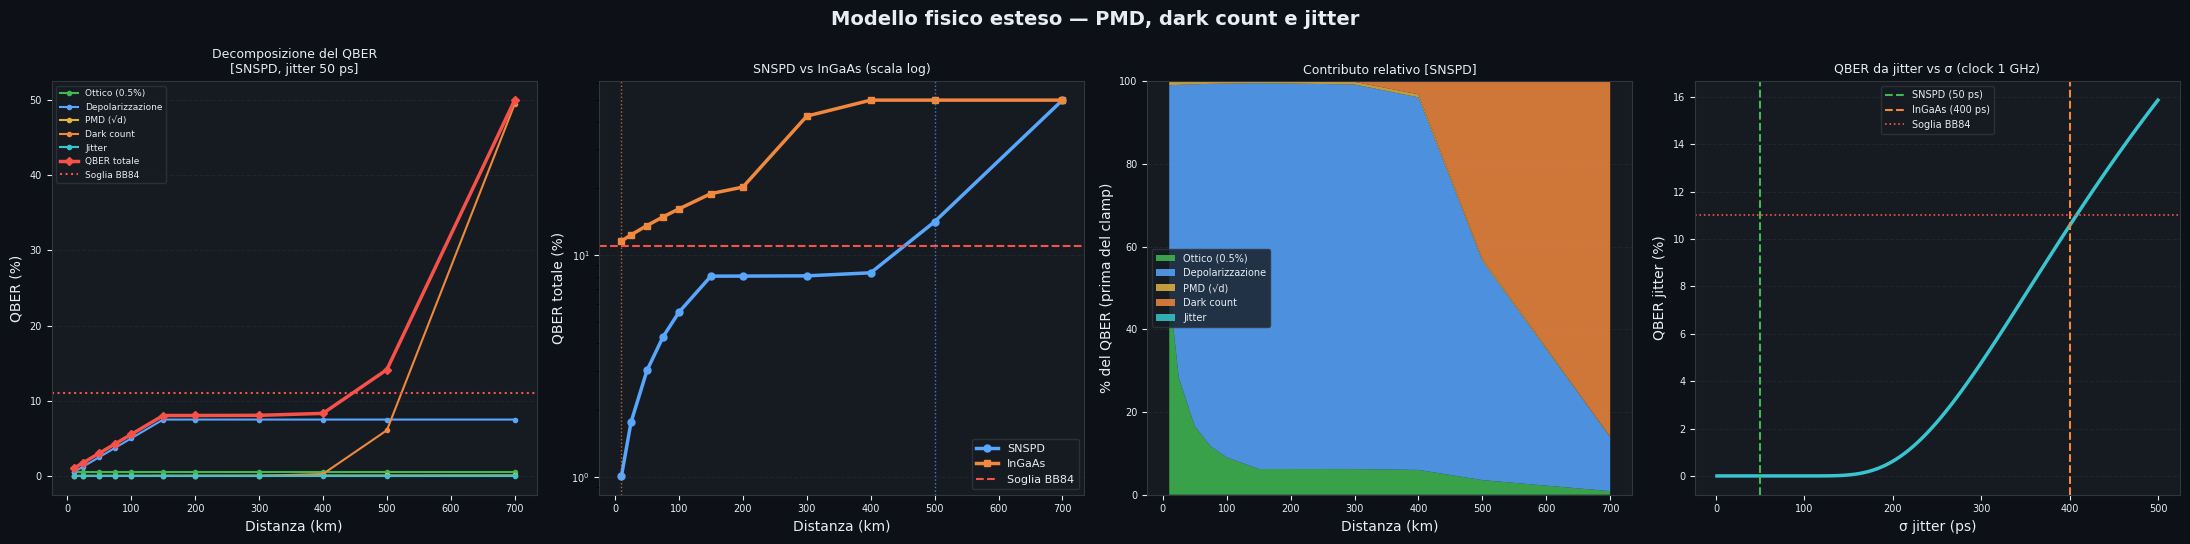

In [31]:
_phys_d = [10, 25, 50, 75, 100, 150, 200, 300, 400, 500, 700]
phys_snspd = run_physical_model_analysis(_phys_d, base_noise=0.001, detector_snspd=True)
phys_ingaas = run_physical_model_analysis(_phys_d, base_noise=0.001, detector_snspd=False)
det_comp = run_detector_comparison([10, 50, 100, 200, 300, 500, 700], base_noise=0.001)
plot_physical_model(phys_snspd, phys_ingaas, det_comp)

### Fase 6G · Decoy states

In [32]:
decoy_results = run_decoy_analysis([10, 20, 30, 50, 75, 100, 150, 200], MU_SIGNAL, MU_DECOY1, noise_rate=0.04)


══════════════════════════════════════════════════════════════════════════════
  DECOY STATES — key rate LMC vs sorgente ideale (mu_s=0.5, mu_d=0.1)
══════════════════════════════════════════════════════════════════════════════
    Dist |      Q_s |   E_s% |        Q1 |    e1% |     R_LMC |   R_ideal | R_LMC/R_id
  ──────────────────────────────────────────────────────────────────────────────
     10km |  0.27716 |  2.50% |  0.194030 |  2.71% |  0.104907 |  0.183671 |       0.57
     20km |  0.20872 |  2.50% |  0.139456 |  2.75% |  0.073293 |  0.138315 |       0.53
     30km |  0.15537 |  2.50% |  0.100279 |  2.77% |  0.051534 |  0.102959 |       0.50
     50km |  0.08410 |  2.50% |  0.051938 |  2.81% |  0.025889 |  0.055729 |       0.46
     75km |  0.03807 |  2.50% |  0.022877 |  2.83% |  0.011177 |  0.025227 |       0.44
    100km |  0.01700 |  2.50% |  0.010093 |  2.84% |  0.004885 |  0.011267 |       0.43
    150km |  0.00334 |  2.50% |  0.001968 |  2.85% |  0.000947 |  0.002215 

### Fase 6H · Attacco man-in-the-middle attivo
`num_bits` allineato al resto della pipeline: con 300 impulsi il campione è troppo piccolo e i conteggi fluttuano.

In [33]:
mitm_results = simulate_mitm_comparison(num_bits=NUM_BITS, distance=30.0, noise_rate=0.04)


══════════════════════════════════════════════════════════════════════
  ATTACCO MITM ATTIVO — confronto senza/con ML-DSA-65
══════════════════════════════════════════════════════════════════════

  SCENARIO 1: senza autenticazione del canale classico
  Bit siftati attesi senza Eve: 356
  Bit di Bob compromessi (MITM): 383
  QBER apparente: 1.31% (solo rumore Eve→Bob, soglia 11.0%) ← EVE INVISIBILE
  Chiave Bob vs chiave Eve: 5 bit diversi su 383 (solo rumore, che Eve corregge con la riconciliazione come farebbe Alice)

  SCENARIO 2: con autenticazione ML-DSA-65 (liboqs)
  Chiave pubblica Alice: 07fd536fcb696be7... (1952B) | firma: 3309B
  Messaggio autentico di Alice accettato:  ✓
  Firma di Alice riusata su basi di Eve:   ✓ rifiutata
  Basi di Eve firmate da Eve stessa:       ✓ rifiutate
  MITM bloccato: ✓ SÌ


### Fase 7 · QBER in funzione della frazione intercettata da Eve

In [34]:
intercept_results = run_intercept_rate_analysis(num_bits=NUM_BITS, distance=30.0, noise_rate=0.04, n_runs=5)


══════════════════════════════════════════════════════════════════════
  ANALISI INTERCEPT RATE — QBER vs frazione intercettata
══════════════════════════════════════════════════════════════════════
       η | BB84 QBER μ |      σ |       BB84 | SSP QBER μ |      σ |        SSP
  ──────────────────────────────────────────────────────────────────────────
      0% |       2.08% |  0.37% | ✓ nascosta |      2.99% |  1.26% | ✓ nascosta
     10% |       4.55% |  1.29% | ✓ nascosta |      5.76% |  1.55% | ✓ nascosta
     20% |       6.79% |  0.98% | ✓ nascosta |      9.50% |  0.56% | ✓ nascosta
     30% |       8.90% |  1.30% | ✓ nascosta |     12.10% |  1.12% | ✓ nascosta
     40% |      11.25% |  1.58% | ✗ rilevata |     12.78% |  2.28% | ✗ rilevata
     50% |      14.38% |  2.59% | ✗ rilevata |     18.33% |  0.90% | ✗ rilevata
     60% |      16.06% |  1.73% | ✗ rilevata |     21.24% |  1.70% | ✗ rilevata
     80% |      20.97% |  1.92% | ✗ rilevata |     27.79% |  2.75% | ✗ rilevata
   

### Fase 8 · Dashboard (12 pannelli)


════════════════════════════════════════════════════════════
  FASE 8: DASHBOARD — 12 pannelli
════════════════════════════════════════════════════════════

[GRAFICO] Dashboard salvato: /home/franciscodev/progetto_bb84/qkd_output/qkd_dashboard_final.png


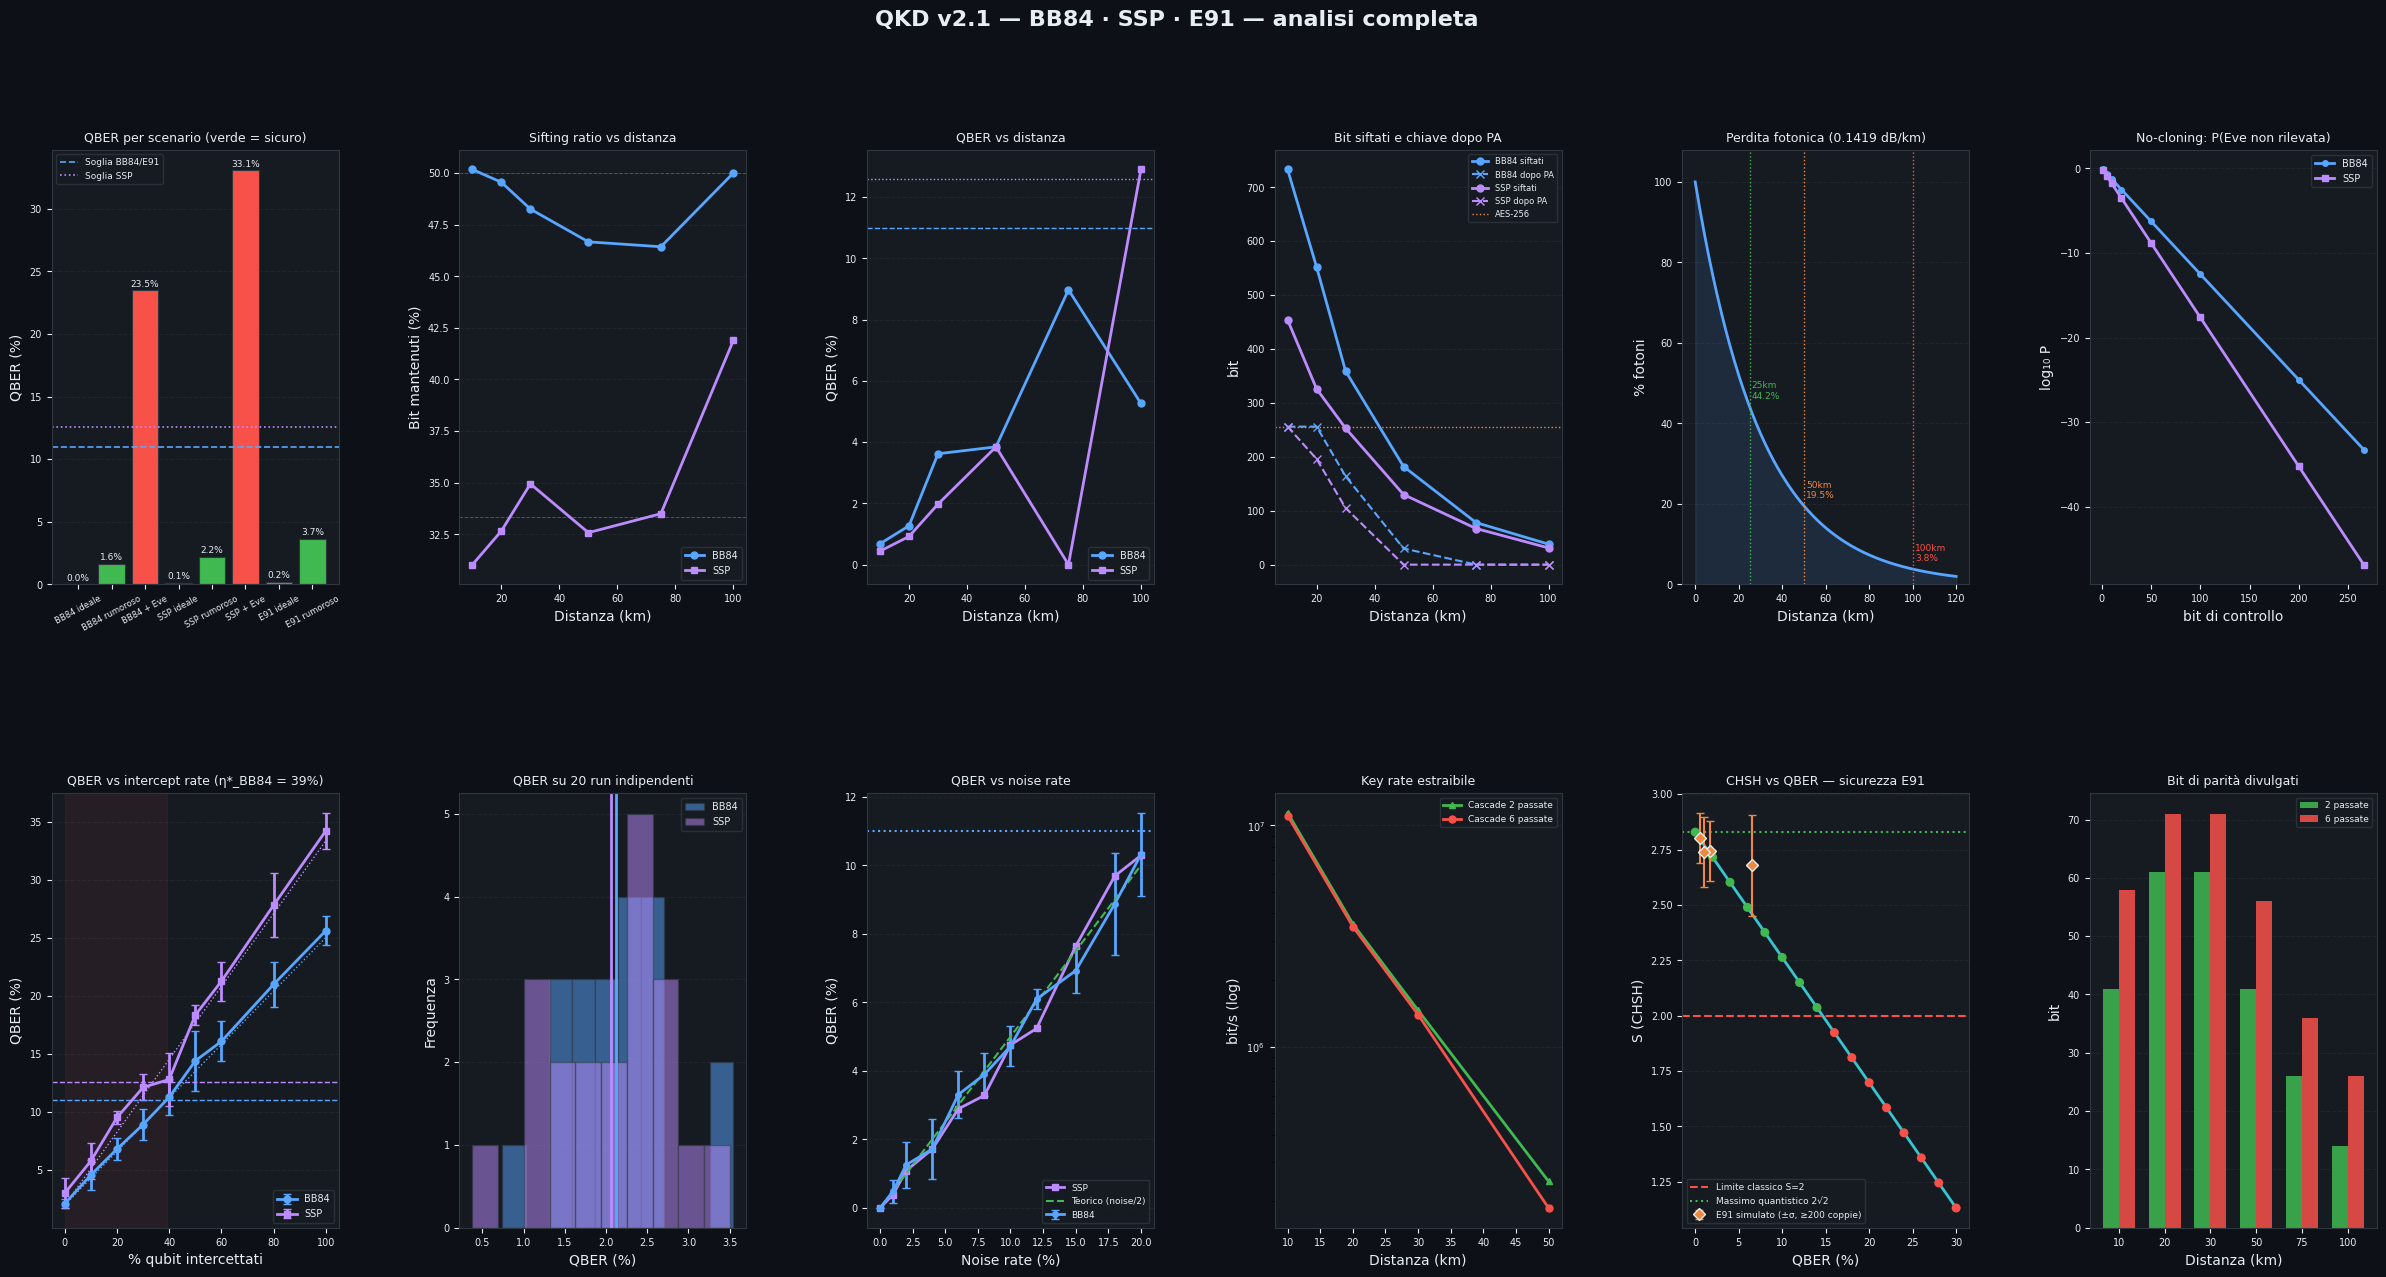

In [35]:
banner("FASE 8: DASHBOARD — 12 pannelli", 60)
plot_dashboard(scenarios, dist_results, nc, intercept_results, stat_results, noise_results,
               cascade_cost_results, pa_results, chsh_analysis, e91_vs_bb84)

### Fase 9 · Conclusioni e raccolta dei risultati

In [36]:
e91_summary = next((s for s in scenarios if s["mode"] == "E91 rumoroso"), None)
print_conclusions(stat_results, intercept_results, nc, dist_results, cascade_cost_results, mitm_results,
                  decoy_results, e91_summary, pa_results=pa_results, e91_vs_bb84=e91_vs_bb84)

_final_results = {
    "scenarios": scenarios, "dist_results": dist_results, "long_haul_results": long_haul_results,
    "e2e_results": e2e_results, "cascade_cost_results": cascade_cost_results, "mitm_results": mitm_results,
    "decoy_results": decoy_results, "chsh_analysis": chsh_analysis, "e91_vs_bb84": e91_vs_bb84,
    "sig_soundness": sig_soundness, "sig_benchmark": sig_benchmark,
    "pq_backend": {"signature": SIGNATURE_BACKEND, "sig_alg": SIG_ALG_ACTIVE,
                   "kem": KEM_BACKEND, "kem_alg": KEM_ALG_ACTIVE},
}



╔══════════════════════════════════════════════════════════════════════════╗
║              CONCLUSIONI E DISCUSSIONE DEI RISULTATI — v2.1              ║
╚══════════════════════════════════════════════════════════════════════════╝

────────────────────────────────────────────────────────────────────────────
 1. SICUREZZA DEL CANALE IN CONDIZIONI OPERATIVE NORMALI
────────────────────────────────────────────────────────────────────────────

Su 20 run indipendenti a 30 km con noise_rate = 4%:
    BB84  QBER = 2.12% ± 0.67%  | sessioni sicure 100% | chiave media dopo PA 206 bit
    SSP   QBER = 2.06% ± 0.75%  | sessioni sicure 100% | chiave media dopo PA 108 bit

La maggiore varianza di SSP riflette il sifting ridotto (~33% contro ~50%): meno bit su cui
stimare il QBER producono una stima più rumorosa.

────────────────────────────────────────────────────────────────────────────
 2. RICONCILIAZIONE — CASCADE COMPLETO E VERIFICA DELLA CHIAVE
──────────────────────────────────────────────

---
## Registro delle correzioni (v2.0 → v2.1)

**Etichette e testi non coerenti con il codice**
- Prima riga dell'output: diceva `liboqs (SLH-DSA + ML-KEM)` mentre la firma in uso è ML-DSA-65; ora riporta la versione di liboqs, e l'algoritmo è stampato dal Modulo 3C.
- Intestazione, docstring del MITM e commenti indicavano SLH-DSA/SPHINCS+ come firma attiva: ora indicano ML-DSA-65 come default e SLH-DSA come alternativa. Le chiavi `scenario_with_sphincs`/`sphincs` diventano `scenario_with_auth`/`auth` (`stats["sphincs"]` resta come alias).
- Commento "liboqs presente ma senza SLH-DSA: prova ML-DSA" invertito rispetto al codice.
- Tempi SLH-DSA incoerenti tra due docstring (~150 ms e ~367 ms): rimossi, li misura il benchmark della Fase 0.
- Etichette "Key length" che in realtà erano bit siftati; "semplificato" usato per il Cascade adattivo a 2 passate; "K1 + BB84" anche per SSP/E91; "BB84 →" nell'intestazione della pipeline che esegue anche SSP; parametro `s_values` che conteneva QBER (ora `qber_values`, il vecchio nome resta accettato).
- Limiti operativi scritti a mano ("BB84 ~120km | SSP ~80km", "> 700km", "← limite fisico") ora ricavati dai dati; la colonna "Limitante" diceva "nessuno" su sessioni non sicure per PA rifiutata.
- Etichetta "Dominante": ignorava il contributo ottico e confrontava i termini in modo incompleto; ora è il massimo dei cinque contributi. Aggiunta la colonna Depol, prima assente benché dominante.
- Conclusione (d) "E91 soggetto a perdita fotonica maggiore (due tratte da d/2)": falsa, $P(d/2)^2=P(d)$. Lo svantaggio reale nel modello è il sifting 2/9.
- Testi delle conclusioni con numeri fissi ("20 run", "4%", "penalità 2×", "propagazione troncata") ora letti dai risultati.

**Librerie**
- `import pyspx` fuori dal `try`: senza pyspx il notebook si bloccava anche con liboqs installato. Ora pyspx è importato solo come fallback.
- Doppio rilevamento di liboqs (inizio file e Modulo 3C) unificato.
- Con liboqs ≥ 0.14 SLH-DSA si chiama `SLH_DSA_PURE_SHAKE_128S`: il nome non era tra gli alias, quindi il benchmark saltava SLH-DSA in silenzio (nell'output salvato compariva solo ML-DSA-65). Alias aggiunto, e un algoritmo assente ora viene segnalato.
- Il KEM veniva disattivato se liboqs non aveva lo schema di firma; ora firma e KEM sono rilevati separatamente.
- Figure salvate in `/tmp`, che su Windows non esiste: ora in `qkd_output/` accanto al notebook.
- Istruzione `pip install netsquid` senza l'indice di NetSquid: corretta.

**Errori di logica**
- **Cascade**: le copie permutate delle passate precedenti non venivano aggiornate dopo una correzione, quindi la propagazione cascade non scattava quasi mai (e poteva ricorreggere bit già corretti); inoltre le parità già note venivano ridivulgate. Ora la propagazione è completa e le parità note non sono ricontate. Nell'output salvato il 17% delle sessioni restava con errori ("BB84 rumoroso": QBER post-riconciliazione 0.52% dichiarato sicuro).
- **Nessuna verifica della chiave**: una sessione con errori residui era dichiarata sicura con chiavi di Alice e Bob diverse. Aggiunta la verifica con tag hash a 32 bit (contati tra i bit divulgati).
- **Chiave ibrida**: $K_2$ era la chiave riconciliata *prima* della PA, che contiene bit noti a Eve; ora è l'output della PA. Una $K_2$ vuota veniva sostituita in silenzio da byte casuali; ora è un errore.
- **Privacy Amplification**: matrice generata sempre con seme fisso 42 (la garanzia del Leftover Hash Lemma richiede una funzione scelta a caso); era inoltre una matrice di Hankel, non di Toeplitz. Ora seme casuale per sessione (firmato) e vera Toeplitz; il ramo SHA-256 silenzioso è sostituito da un errore esplicito.
- **Firma "parità"**: veniva firmato un solo byte (la parità del *numero* di bit divulgati) e i messaggi 3-4 dichiarati (seme PA, conferma) non venivano firmati. Ora sono firmati tutti e quattro, con le parità reali del Cascade.
- **E91**: rumore applicato due volte (sorgente + canale) e moltiplicato per 1.5 nel confronto con BB84, senza dichiararlo: E91 risultava ~4 volte più rumoroso a parità di canale. Ora stesso rumore di canale; il rumore della sorgente è un parametro separato (default 0). Le statistiche di E91 avevano chiavi diverse da BB84/SSP (`S` invece di `S_chsh`); E91 ignorava jitter e firma.
- **MITM**: QBER apparente scritto a mano a 0% e parametro `noise_rate` ignorato; la chiave "vera" di Bob conteneva le sue basi invece dei bit. Ora il QBER apparente è misurato.
- **Key rate (8F)**: il tetto di 256 bit della chiave AES appiattiva il key rate (0% di differenza a 10-20 km); ora si usano i bit estraibili.
- **η\***: formula incoerente con la curva teorica; QBER di canale stimato su una sola sessione (ora media su `n_runs`).
- AES: Bob decifrava con la chiave di Alice; ora con la propria.

**Snellimento** (tutte le funzioni originali restano disponibili con lo stesso nome)
- Codifica e misura dei qubit in due helper comuni ad Alice, Bob ed Eve; un'unica classe di misura E91.
- Fase quantistica BB84/SSP in `run_prepare_measure_session()`, riusata dal runner e dal Modulo 8F.
- Post-processing comune a BB84, SSP ed E91 in `_postprocess_key()`; rami duplicati rimossi.
- Stile dei grafici, banner e conversione bit→byte in helper condivisi; docstring storiche spostate nelle celle di testo.

### Aggiornamento dopo la prima esecuzione con NetSquid
- **Compatibilità NumPy 1.x**: `uint64 & int` non è ammesso in NumPy 1.x (richiesto da NetSquid); la parità del Cascade ora converte in `int` prima dell'AND.
- **CHSH con incertezza**: S è riportato come $S\pm\sigma_S$ con la distanza dal limite classico in σ (`compute_chsh_uncertainty()`); nella dashboard i punti E91 hanno la barra d'errore. Valori stimati oltre $2\sqrt2$ (3.02 e 3.55 nella prima esecuzione) sono fluttuazioni con ~85 campioni per correlazione.
- **Cascade su chiavi corte**: con QBER basso il blocco iniziale diventava grande quanto la chiave e il 20% delle sessioni veniva abortito dalla verifica, con l'effetto paradossale di meno sessioni sicure a rumore 1-2% che a 4-15%. Ora blocco iniziale ≤ n/4, blocchi ≤ n/2 e 6 passate (`CASCADE_PASSES`): sessioni con errori residui 0.3-2% invece di 8-14%, al costo di ~8-10 bit divulgati.